# Chất lượng, độ phủ và hoạt động GEO

Notebook chứa mã phân tích theo đúng thứ tự từ các file nguồn trong `src/`. Chạy với kernel của `.venv` tại repo. Các bước có thể đọc toàn bộ raw và ghi vào `outputs/`; kiểm tra phạm vi và quy ước thời gian của từng phần trước khi diễn giải. Mã cũ dùng UTC hoặc mẫu là phương pháp cũ, chưa được coi là kết quả Moscow/toàn bộ khách hàng. Script nguồn vẫn được giữ để đối chiếu.

In [1]:
from pathlib import Path
import sys
import time
import pandas as pd
from IPython.display import display, Image, SVG, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'src/scripts'))
sys.path.insert(0, str(ROOT / 'src/mbd_mini_eda_fixes'))
def show_generated_results(started_ns, source):
    changed = sorted((p for base in (ROOT / 'outputs', ROOT / 'docs') if base.exists() for p in base.rglob('*') if p.is_file() and p.stat().st_mtime_ns >= started_ns), key=lambda p: p.as_posix())
    display(Markdown(f'### Kết quả: `{source}`'))
    if not changed:
        display(Markdown('Không có file kết quả mới từ phần này.'))
        return
    images = [p for p in changed if p.suffix.lower() in ('.png', '.jpg', '.jpeg', '.svg')]
    png_stems = {p.with_suffix('') for p in images if p.suffix.lower() == '.png'}
    for p in images:
        if p.suffix.lower() == '.svg' and p.with_suffix('') in png_stems:
            continue
        display(Markdown(f'**{p.relative_to(ROOT).as_posix()}**'))
        display(SVG(filename=str(p)) if p.suffix.lower() == '.svg' else Image(filename=str(p)))
    tables = [p for p in changed if p.suffix.lower() == '.csv']
    for p in tables:
        display(Markdown(f'**{p.relative_to(ROOT).as_posix()}** — 5 dòng đầu'))
        try:
            display(pd.read_csv(p, nrows=5))
        except Exception as exc:
            display(Markdown(f'Không đọc được bảng: `{type(exc).__name__}: {exc}`'))
    others = [p.relative_to(ROOT).as_posix() for p in changed if p not in images and p not in tables]
    if others:
        display(Markdown('File kết quả khác: ' + ', '.join(f'`{p}`' for p in others)))

## Audit Geo Special Values

Nguồn: `src/scripts/audit_geo_special_values.py`. Chạy các ô của phần này theo thứ tự.

In [2]:
__file__ = str(ROOT / 'src/scripts/audit_geo_special_values.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [3]:
"""Audit missing/sentinel codes and high-occupancy cells without assigning semantics."""
from pathlib import Path
import duckdb
import pandas as pd

out = Path('outputs/geo_special_values')
out.mkdir(parents=True, exist_ok=True)
c = duckdb.connect()
c.execute('SET threads=4')
c.execute("SET memory_limit='4GB'")
c.execute("CREATE VIEW geo AS SELECT * FROM read_parquet('data/MBD-mini/detail/geo/**/*.parquet')")
n, clients = c.execute('SELECT count(*),count(distinct client_id) FROM geo').fetchone()
quality, tops, details = [], [], []
for level in [4,5,6]:
    col = f'geohash_{level}'
    q = c.execute(f'''SELECT count(*) FILTER(WHERE {col} IS NULL), min({col}),max({col}),
        count(*) FILTER(WHERE {col}=0),count(*) FILTER(WHERE {col}<0),
        count(*) FILTER(WHERE {col} IN (-1,0,999,9999,99999,999999,2147483647)) FROM geo''').fetchone()
    quality.append(dict(level=f'g{level}',rows=n,nulls=q[0],minimum=q[1],maximum=q[2],zeros=q[3],negative=q[4],conventional_sentinel_rows=q[5]))
    df = pd.read_csv(f'outputs/geo_cell_sizes/g{level}_cell_counts.csv')
    sentinel = df[df.cell.isin([-1,0,1,999,9999,99999,999999,2147483647])].copy()
    sentinel.to_csv(out/f'g{level}_candidate_codes.csv', index=False)
    chosen = set()
    for metric in ['events','customers']:
        top = df.nlargest(10,metric).copy()
        top['rank_by'] = metric
        top['level'] = f'g{level}'
        top['event_pct'] = top.events/n*100
        top['customer_pct'] = top.customers/clients*100
        top['events_per_customer'] = top.events/top.customers
        tops.append(top)
        chosen.update(top.cell.tolist())
    codes = ','.join(str(int(v)) for v in sorted(chosen))
    # Per-customer concentration distinguishes breadth from repeated activity.
    d = c.execute(f'''WITH pc AS (
        SELECT {col} cell, client_id,count(*) n FROM geo WHERE {col} IN ({codes}) GROUP BY 1,2
    ) SELECT cell,max(n) max_events_one_customer,
       max(n)*100.0/sum(n) largest_customer_event_pct,
       median(n) median_events_per_customer FROM pc GROUP BY cell''').df()
    d['level']=f'g{level}'
    details.append(d)
    print(f'g{level} complete',flush=True)
pd.DataFrame(quality).to_csv(out/'quality.csv',index=False)
pd.concat(tops).merge(pd.concat(details),on=['level','cell']).to_csv(out/'top_cells.csv',index=False)
print(pd.DataFrame(quality).to_string(index=False))
t = pd.read_csv(out/'top_cells.csv')
print(t.groupby(['level','rank_by'],sort=False).head(1).to_string(index=False))

g4 complete


g5 complete


g6 complete


level     rows  nulls  minimum  maximum  zeros  negative  conventional_sentinel_rows
   g4 66295724      0       12    53808      0         0                           0
   g5 66295724      0        5   428058      0         0                           9
   g6 66295724      0        1  2936555      0         0                          46
   cell  events  customers   rank_by level  event_pct  customer_pct  events_per_customer  max_events_one_customer  largest_customer_event_pct  median_events_per_customer
   3808 4030283      24156    events    g4   6.079250     33.285106           166.843973                    13422                    0.333029                        22.0
   3808 4030283      24156 customers    g4   6.079250     33.285106           166.843973                    13422                    0.333029                        22.0
 198378  470791      13713    events    g5   0.710138     18.895457            34.331729                     3705                    0.786973         

In [4]:
show_generated_results(__eda_started_ns, 'src/scripts/audit_geo_special_values.py')

### Kết quả: `src/scripts/audit_geo_special_values.py`

**outputs/geo_special_values/g4_candidate_codes.csv** — 5 dòng đầu

,cell,events,customers


**outputs/geo_special_values/g5_candidate_codes.csv** — 5 dòng đầu

,cell,events,customers
0,9999,9,8


**outputs/geo_special_values/g6_candidate_codes.csv** — 5 dòng đầu

,cell,events,customers
0,1,1,1
1,999999,45,3
2,999,1,1


**outputs/geo_special_values/quality.csv** — 5 dòng đầu

,level,rows,nulls,minimum,maximum,zeros,negative,conventional_sentinel_rows
0,g4,66295724,0,12,53808,0,0,0
1,g5,66295724,0,5,428058,0,0,9
2,g6,66295724,0,1,2936555,0,0,46


**outputs/geo_special_values/top_cells.csv** — 5 dòng đầu

,cell,events,customers,rank_by,level,event_pct,customer_pct,events_per_customer,max_events_one_customer,largest_customer_event_pct,median_events_per_customer
0,3808,4030283,24156,events,g4,6.079250,33.285106,166.843973,13422,0.333029,22.0
1,14652,2688866,18630,events,g4,4.055866,25.670704,144.329898,12961,0.482025,16.0
2,4098,2563265,23117,events,g4,3.866411,31.853444,110.882251,5297,0.206651,15.0
3,25915,1953236,13883,events,g4,2.946247,19.129704,140.692646,19048,0.975202,17.0
4,12936,1903767,16555,events,g4,2.871629,22.811514,114.996497,11108,0.583475,14.0


## Analyze Geo Cell Sizes

Nguồn: `src/scripts/analyze_geo_cell_sizes.py`. Chạy các ô của phần này theo thứ tự.

In [5]:
__file__ = str(ROOT / 'src/scripts/analyze_geo_cell_sizes.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [6]:
"""Full-source descriptive geo cell occupancy; no prediction cutoff is applied."""
from pathlib import Path
import math
import duckdb
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

OUT = Path('outputs/geo_cell_sizes')
OUT.mkdir(parents=True, exist_ok=True)
con = duckdb.connect()
con.execute("SET threads=4")
con.execute("SET memory_limit='4GB'")
con.execute("CREATE VIEW geo AS SELECT * FROM read_parquet('data/MBD-mini/detail/geo/**/*.parquet')")
scope = con.execute('SELECT count(*), count(distinct client_id), min(event_time), max(event_time) FROM geo').fetchone()
print('scope:', scope, flush=True)

def gini(values):
    x = np.sort(np.asarray(values, dtype=float))
    return float(2 * np.dot(np.arange(1, len(x)+1), x) / (len(x)*x.sum()) - (len(x)+1)/len(x))

rows = []
fig, axes = plt.subplots(2, 3, figsize=(15, 9), dpi=180)
for i, level in enumerate([4, 5, 6]):
    df = con.execute(f'SELECT geohash_{level} cell, count(*) events, count(distinct client_id) customers FROM geo WHERE geohash_{level} IS NOT NULL GROUP BY 1').df()
    df.to_csv(OUT/f'g{level}_cell_counts.csv', index=False)
    df.nlargest(20, 'customers').to_csv(OUT/f'g{level}_top20_customers.csv', index=False)
    for j, metric in enumerate(['events', 'customers']):
        x = df[metric].to_numpy()
        n_top = max(1, math.ceil(len(x)*.01))
        rows.append(dict(level=f'g{level}', metric=metric, cells=len(x), total=int(x.sum()),
            median=float(np.median(x)), p90=float(np.quantile(x,.9)), p99=float(np.quantile(x,.99)),
            maximum=int(x.max()), gini=gini(x), singleton_pct=float((x==1).mean()*100),
            le5_pct=float((x<=5).mean()*100), top1pct_cells=n_top,
            top1pct_share=float(np.sort(x)[-n_top:].sum()/x.sum()*100)))
        # Empirical complementary CDF: retains singletons and avoids bin-width artifacts.
        sizes, freq = np.unique(x, return_counts=True)
        survival = np.cumsum(freq[::-1])[::-1]/len(x)
        ax = axes[j,i]
        ax.loglog(sizes, survival, color=['#2864a0','#208575'][j], lw=1.8)
        ax.set_title(f'g{level} · {len(df):,} observed cells')
        ax.set_xlabel('Events per cell' if metric=='events' else 'Distinct customers per cell')
        ax.set_ylabel('Fraction of cells with size >= x')
        ax.grid(True, which='both', alpha=.15)
        ax.text(.05,.07,f'Gini = {gini(x):.3f}',transform=ax.transAxes)
    print(f'g{level} complete', flush=True)
summary = pd.DataFrame(rows)
summary.to_csv(OUT/'summary.csv', index=False)
fig.suptitle('Geo cell occupancy: empirical CCDF on log-log axes', fontsize=18)
fig.tight_layout(rect=(0,.03,1,.95))
fig.text(.02,.015,'All detail/geo events across 5 folds. Customers are distinct within each cell; a customer may visit multiple cells.', fontsize=10)
fig.savefig(OUT/'cell_size_loglog.png')
plt.close(fig)
(OUT/'scope.txt').write_text(f'Events: {scope[0]}\nDistinct customers: {scope[1]}\nEvent time: {scope[2]} through {scope[3]}\nObserved non-null cells only. No event deduplication. Full-source descriptive EDA, not cutoff-specific model features.\nCustomer sums represent customer-cell memberships, not unique people. Top 1% uses ceil(0.01 * observed cell count), ranked separately per metric.\n', encoding='utf-8')
print(summary.to_string(index=False))

scope: (66295724, 72573, datetime.datetime(2021, 12, 11, 19, 27, 7, 507106), datetime.datetime(2022, 12, 31, 20, 59, 58, 725788))


g4 complete


g5 complete


g6 complete


level    metric  cells    total  median    p90      p99  maximum     gini  singleton_pct   le5_pct  top1pct_cells  top1pct_share
   g4    events  18948 66295724    23.0 1489.3 50968.57  4030283 0.971616      12.819295 30.362043            190      77.728615
   g4 customers  18948   911230     3.0   69.0   753.06    24156 0.883872      31.808106 58.597213            190      45.625583
   g5    events 122982 66295724     6.0  260.0  8408.19   470791 0.965134      21.590151 47.265453           1230      73.264111
   g5 customers 122982  2273943     2.0   23.0   280.00    14483 0.865010      42.925794 73.118830           1230      49.534751
   g6    events 610866 66295724     3.0  100.0  2494.00    53223 0.929318      29.913271 58.790635           6109      49.924338
   g6 customers 610866  5790285     1.0   13.0   168.00     4112 0.811744      51.997983 81.046907           6109      38.707093


### Kết quả: `src/scripts/analyze_geo_cell_sizes.py`

**outputs/geo_cell_sizes/cell_size_loglog.png**

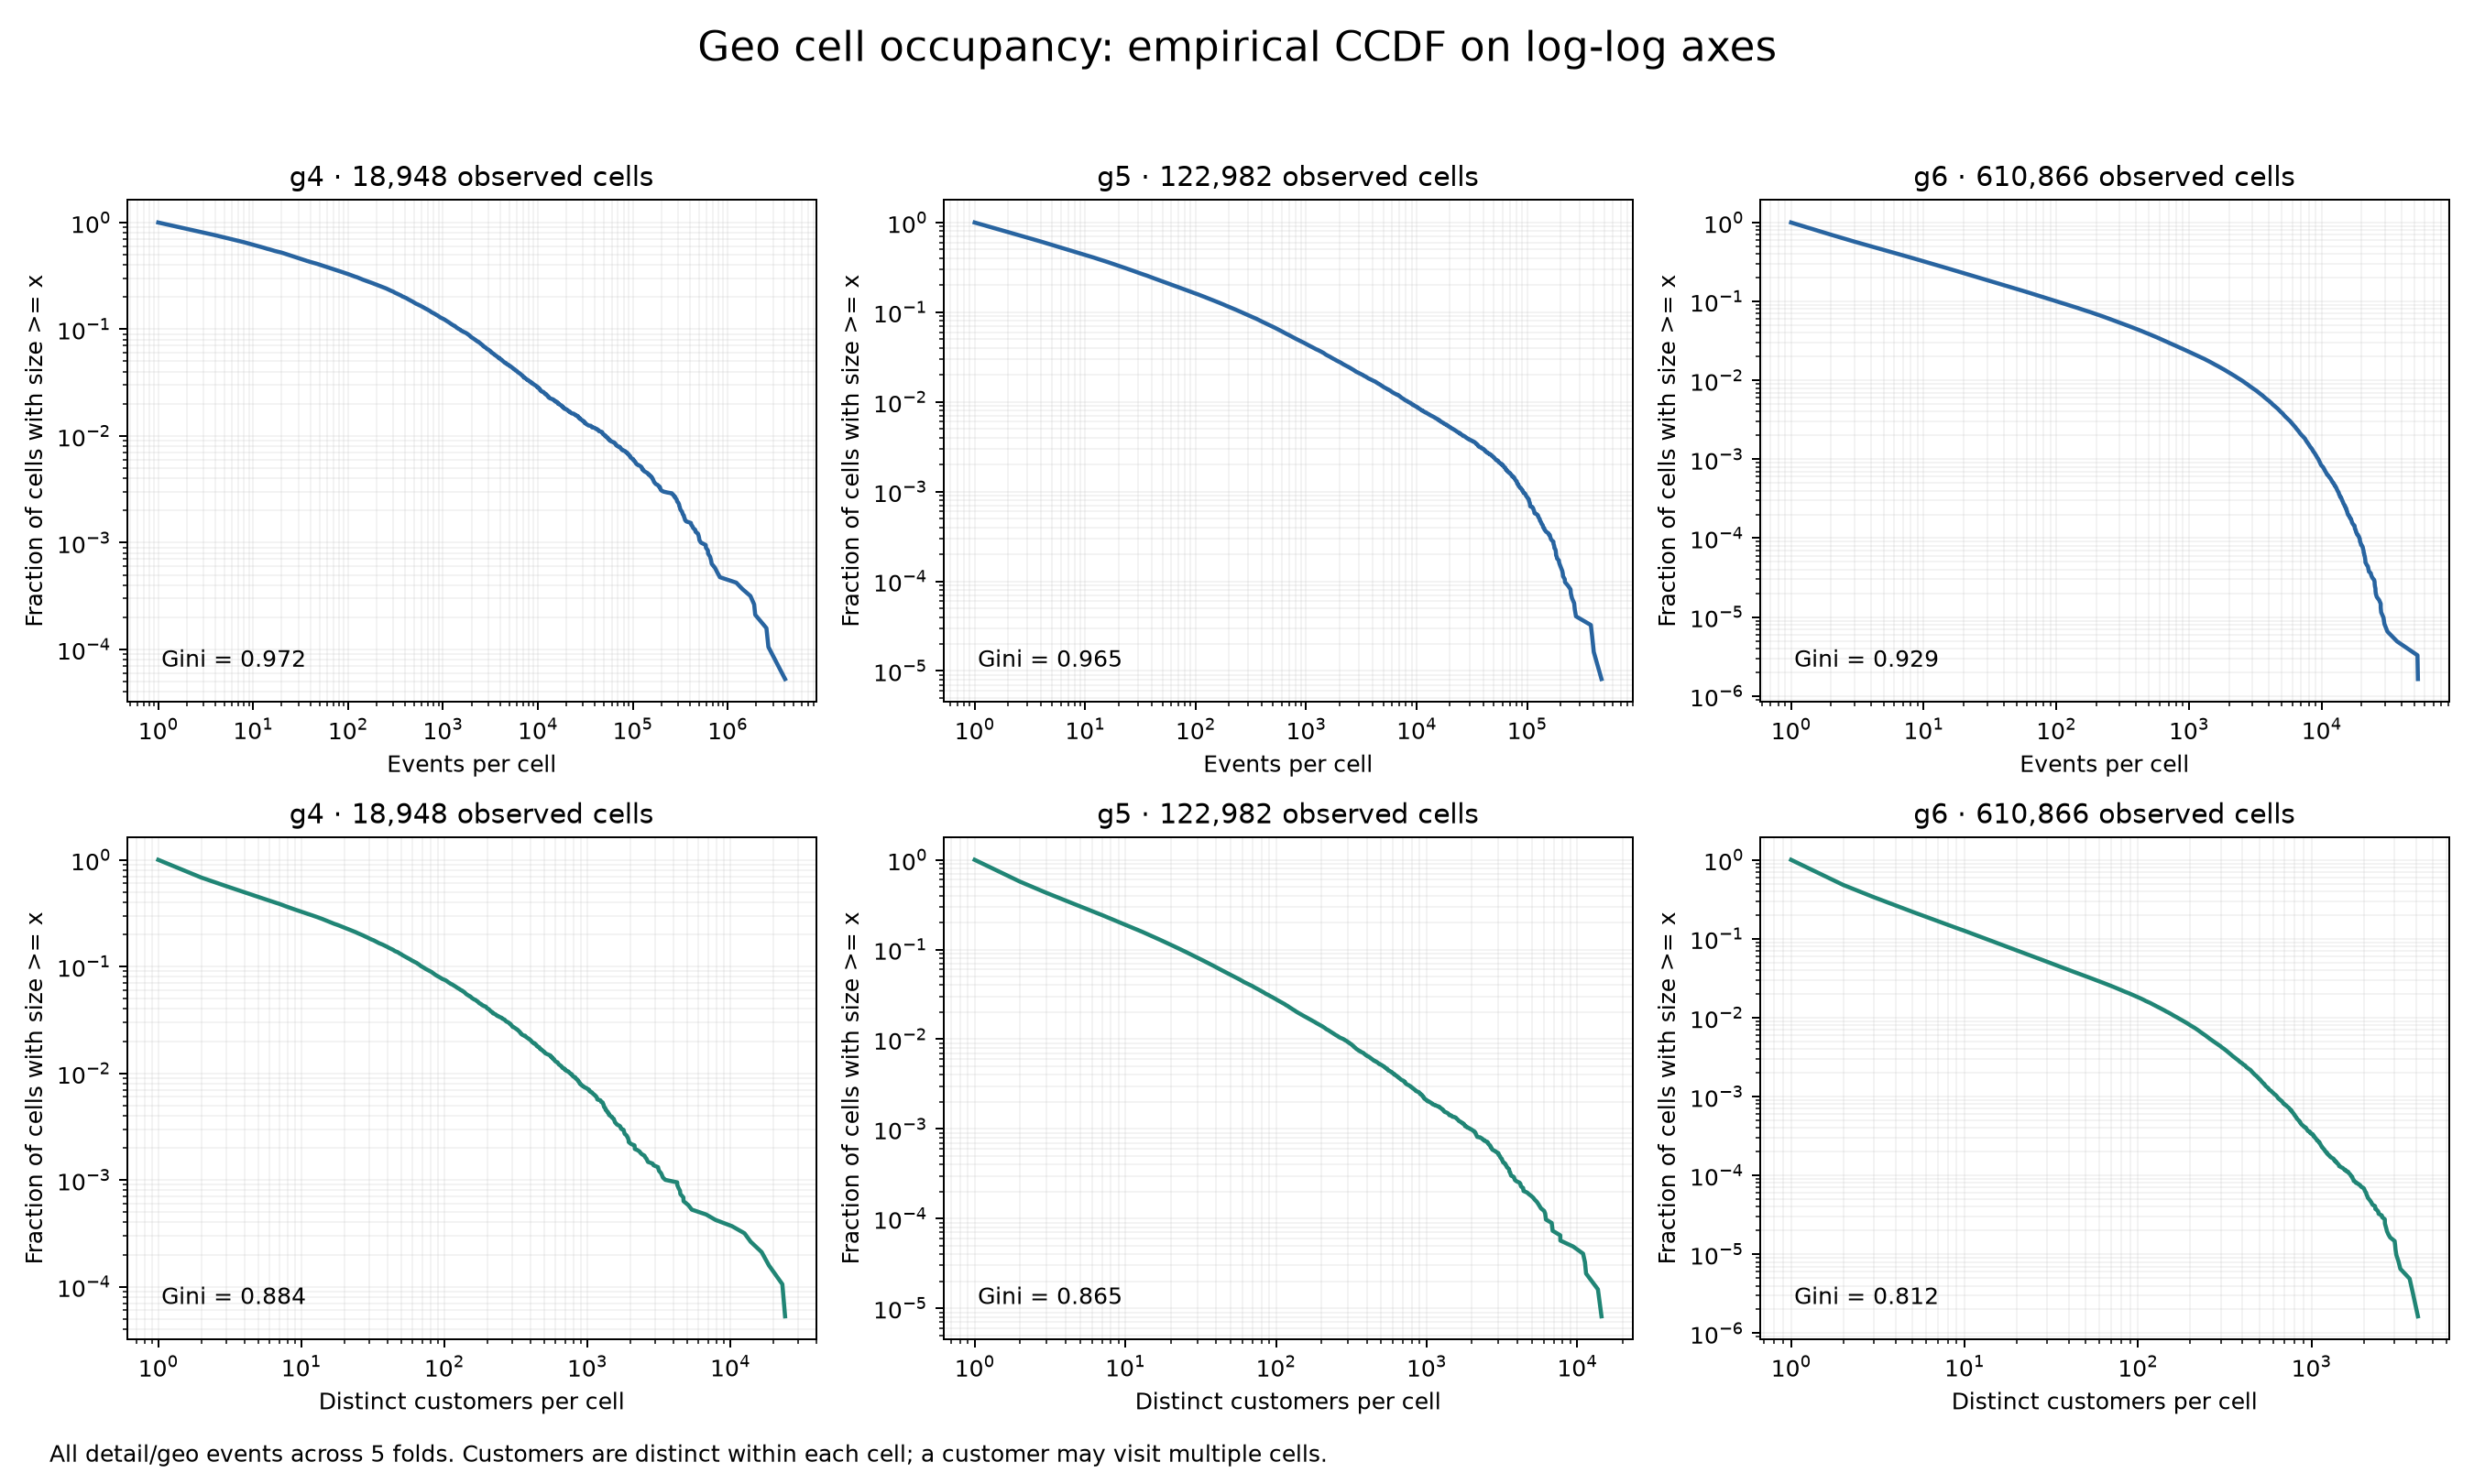

**outputs/geo_cell_sizes/g4_cell_counts.csv** — 5 dòng đầu

,cell,events,customers
0,48705,230632,2860
1,5744,653320,2148
2,35758,30967,1420
3,31534,13033,404
4,26,736412,2413


**outputs/geo_cell_sizes/g4_top20_customers.csv** — 5 dòng đầu

,cell,events,customers
0,3808,4030283,24156
1,4098,2563265,23117
2,14652,2688866,18630
3,12936,1903767,16555
4,25915,1953236,13883


**outputs/geo_cell_sizes/g5_cell_counts.csv** — 5 dòng đầu

,cell,events,customers
0,73596,311,77
1,408894,2052,345
2,356415,2662,97
3,27783,165,6
4,299750,19,3


... (5 outputs left out)

,cell,events,customers
0,2929236,29269,4112
1,2423580,21208,3840
2,2522598,23852,3683
3,155121,53223,3257
4,751280,17130,3174


**outputs/geo_cell_sizes/summary.csv** — 5 dòng đầu

,level,metric,cells,total,median,p90,p99,maximum,gini,singleton_pct,le5_pct,top1pct_cells,top1pct_share
0,g4,events,18948,66295724,23.0,1489.3,50968.57,4030283,0.971616,12.819295,30.362043,190,77.728615
1,g4,customers,18948,911230,3.0,69.0,753.06,24156,0.883872,31.808106,58.597213,190,45.625583
2,g5,events,122982,66295724,6.0,260.0,8408.19,470791,0.965134,21.590151,47.265453,1230,73.264111
3,g5,customers,122982,2273943,2.0,23.0,280.00,14483,0.865010,42.925794,73.118830,1230,49.534751
4,g6,events,610866,66295724,3.0,100.0,2494.00,53223,0.929318,29.913271,58.790635,6109,49.924338


File kết quả khác: `outputs/geo_cell_sizes/scope.txt`

In [7]:
show_generated_results(__eda_started_ns, 'src/scripts/analyze_geo_cell_sizes.py')

## Analyze Geo Temporal Coverage

Nguồn: `src/scripts/analyze_geo_temporal_coverage.py`. Chạy các ô của phần này theo thứ tự.

In [8]:
__file__ = str(ROOT / 'src/scripts/analyze_geo_temporal_coverage.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [9]:
"""Monthly raw geo coverage and first-observed code diagnostics (UTC convention)."""
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

out = Path('outputs/geo_temporal_coverage')
out.mkdir(parents=True, exist_ok=True)
c = duckdb.connect()
c.execute('SET threads=4')
c.execute("SET memory_limit='4GB'")
c.execute("CREATE VIEW geo AS SELECT *,date_trunc('month',event_time)::DATE AS month FROM read_parquet('data/MBD-mini/detail/geo/**/*.parquet')")
denom = c.execute("SELECT count(distinct client_id) FROM read_parquet('data/MBD-mini/client_split/**/*.parquet')").fetchone()[0]
coverage = c.execute('''SELECT month,count(*) events,count(distinct client_id) active_clients,
    count(distinct cast(event_time AS DATE)) observed_days,min(event_time) first_event,max(event_time) last_event
    FROM geo GROUP BY month ORDER BY month''').df()
months = pd.date_range(coverage.month.min(),coverage.month.max(),freq='MS')
coverage = coverage.set_index('month').reindex(months).rename_axis('month').reset_index()
coverage['reference_clients']=denom
coverage['coverage_pct']=coverage.active_clients/denom*100
coverage['events_per_active_client']=coverage.events/coverage.active_clients
coverage.to_csv(out/'monthly_coverage.csv',index=False)
tables=[]
for level in [4,5,6]:
    col=f'geohash_{level}'
    c.execute(f'''CREATE OR REPLACE TEMP TABLE cm AS SELECT month,{col} cell,count(*) events
        FROM geo WHERE {col} IS NOT NULL GROUP BY 1,2''')
    c.execute('CREATE OR REPLACE TEMP TABLE first_seen AS SELECT cell,min(month) first_month FROM cm GROUP BY cell')
    df = c.execute('''SELECT cm.month,count(*) active_cells,
        count(*) FILTER(WHERE cm.month=f.first_month) new_cells,
        sum(cm.events) FILTER(WHERE cm.month=f.first_month) events_in_new_cells,
        count(*) FILTER(WHERE prev.cell IS NOT NULL) retained_from_previous
        FROM cm JOIN first_seen f USING(cell)
        LEFT JOIN cm prev ON prev.cell=cm.cell AND prev.month=cm.month-INTERVAL '1 month'
        GROUP BY cm.month ORDER BY cm.month''').df()
    df=df.set_index('month').reindex(months).rename_axis('month').reset_index()
    df['level']=f'g{level}'
    df['new_pct']=df.new_cells/df.active_cells*100
    df['cumulative_seen']=df.new_cells.cumsum()
    df['new_cell_event_pct']=df.events_in_new_cells.fillna(0)/coverage.events*100
    df['previous_month_cells']=df.active_cells.shift(1)
    df['previous_month_retention_pct']=df.retained_from_previous/df.previous_month_cells*100
    df['jaccard_previous_pct']=df.retained_from_previous/(df.active_cells+df.previous_month_cells-df.retained_from_previous)*100
    tables.append(df)
    print(f'g{level} complete',flush=True)
cells=pd.concat(tables,ignore_index=True)
cells.to_csv(out/'monthly_cells.csv',index=False)
fig,axes=plt.subplots(3,1,figsize=(12,11),dpi=160,sharex=True)
axes[0].plot(coverage.month,coverage.coverage_pct,marker='o',color='#2864a0')
axes[0].set_ylabel('Customers with geo (%)')
axes[0].yaxis.set_major_formatter(PercentFormatter(100))
axes[0].set_ylim(bottom=0)
for level,color in zip(['g4','g5','g6'],['#2864a0','#208575','#c17b33']):
    d=cells[cells.level==level]
    axes[1].plot(d.month,d.new_cells,marker='o',label=level,color=color)
    axes[2].plot(d.month,d.new_pct,marker='o',label=level,color=color)
axes[1].set_ylabel('First-observed cells (log scale)')
axes[1].set_yscale('log')
axes[1].legend(ncol=3)
axes[2].set_ylabel('New / active cells (%)')
axes[2].yaxis.set_major_formatter(PercentFormatter(100))
axes[2].set_xticks(months,months.strftime('%m/%Y'),rotation=35,ha='right')
for ax in axes:
    ax.grid(alpha=.2)
    ax.axvspan(months[0],months[0]+pd.offsets.MonthEnd(0),color='grey',alpha=.12)
fig.suptitle(f'Monthly geo coverage and first-observed cells | {denom:,} reference customers',fontsize=15)
fig.tight_layout(rect=(0,.04,1,.96))
fig.text(.02,.01,'12/2021 is partial and initializes the observed vocabulary. New means unseen in all earlier available months; UTC convention.',fontsize=10)
fig.savefig(out/'monthly_coverage_new_cells.png')
print(coverage[['month','events','active_clients','coverage_pct']].to_string(index=False))
print(cells[['month','level','active_cells','new_cells','new_pct','new_cell_event_pct','jaccard_previous_pct']].to_string(index=False))

g4 complete


g5 complete


g6 complete


     month  events  active_clients  coverage_pct
2021-12-01  731236           48685     48.576189
2022-01-01 4321314           59804     59.670338
2022-02-01 5263341           59955     59.821001
2022-03-01 6202143           56329     56.203105
2022-04-01 5466890           58751     58.619692
2022-05-01 5671200           59026     58.894077
2022-06-01 5665455           58367     58.236550
2022-07-01 6044774           59574     59.440852
2022-08-01 6212812           57009     56.881585
2022-09-01 4900032           55353     55.229286
2022-10-01 4860936           58398     58.267481
2022-11-01 5364475           58179     58.048970
2022-12-01 5591116           56426     56.299888
     month level  active_cells  new_cells    new_pct  new_cell_event_pct  jaccard_previous_pct
2021-12-01    g4          6650       6650 100.000000          100.000000                   NaN
2022-01-01    g4          9186       2877  31.319399            0.268182             66.222316
2022-02-01    g4          922

### Kết quả: `src/scripts/analyze_geo_temporal_coverage.py`

**outputs/geo_temporal_coverage/monthly_coverage_new_cells.png**

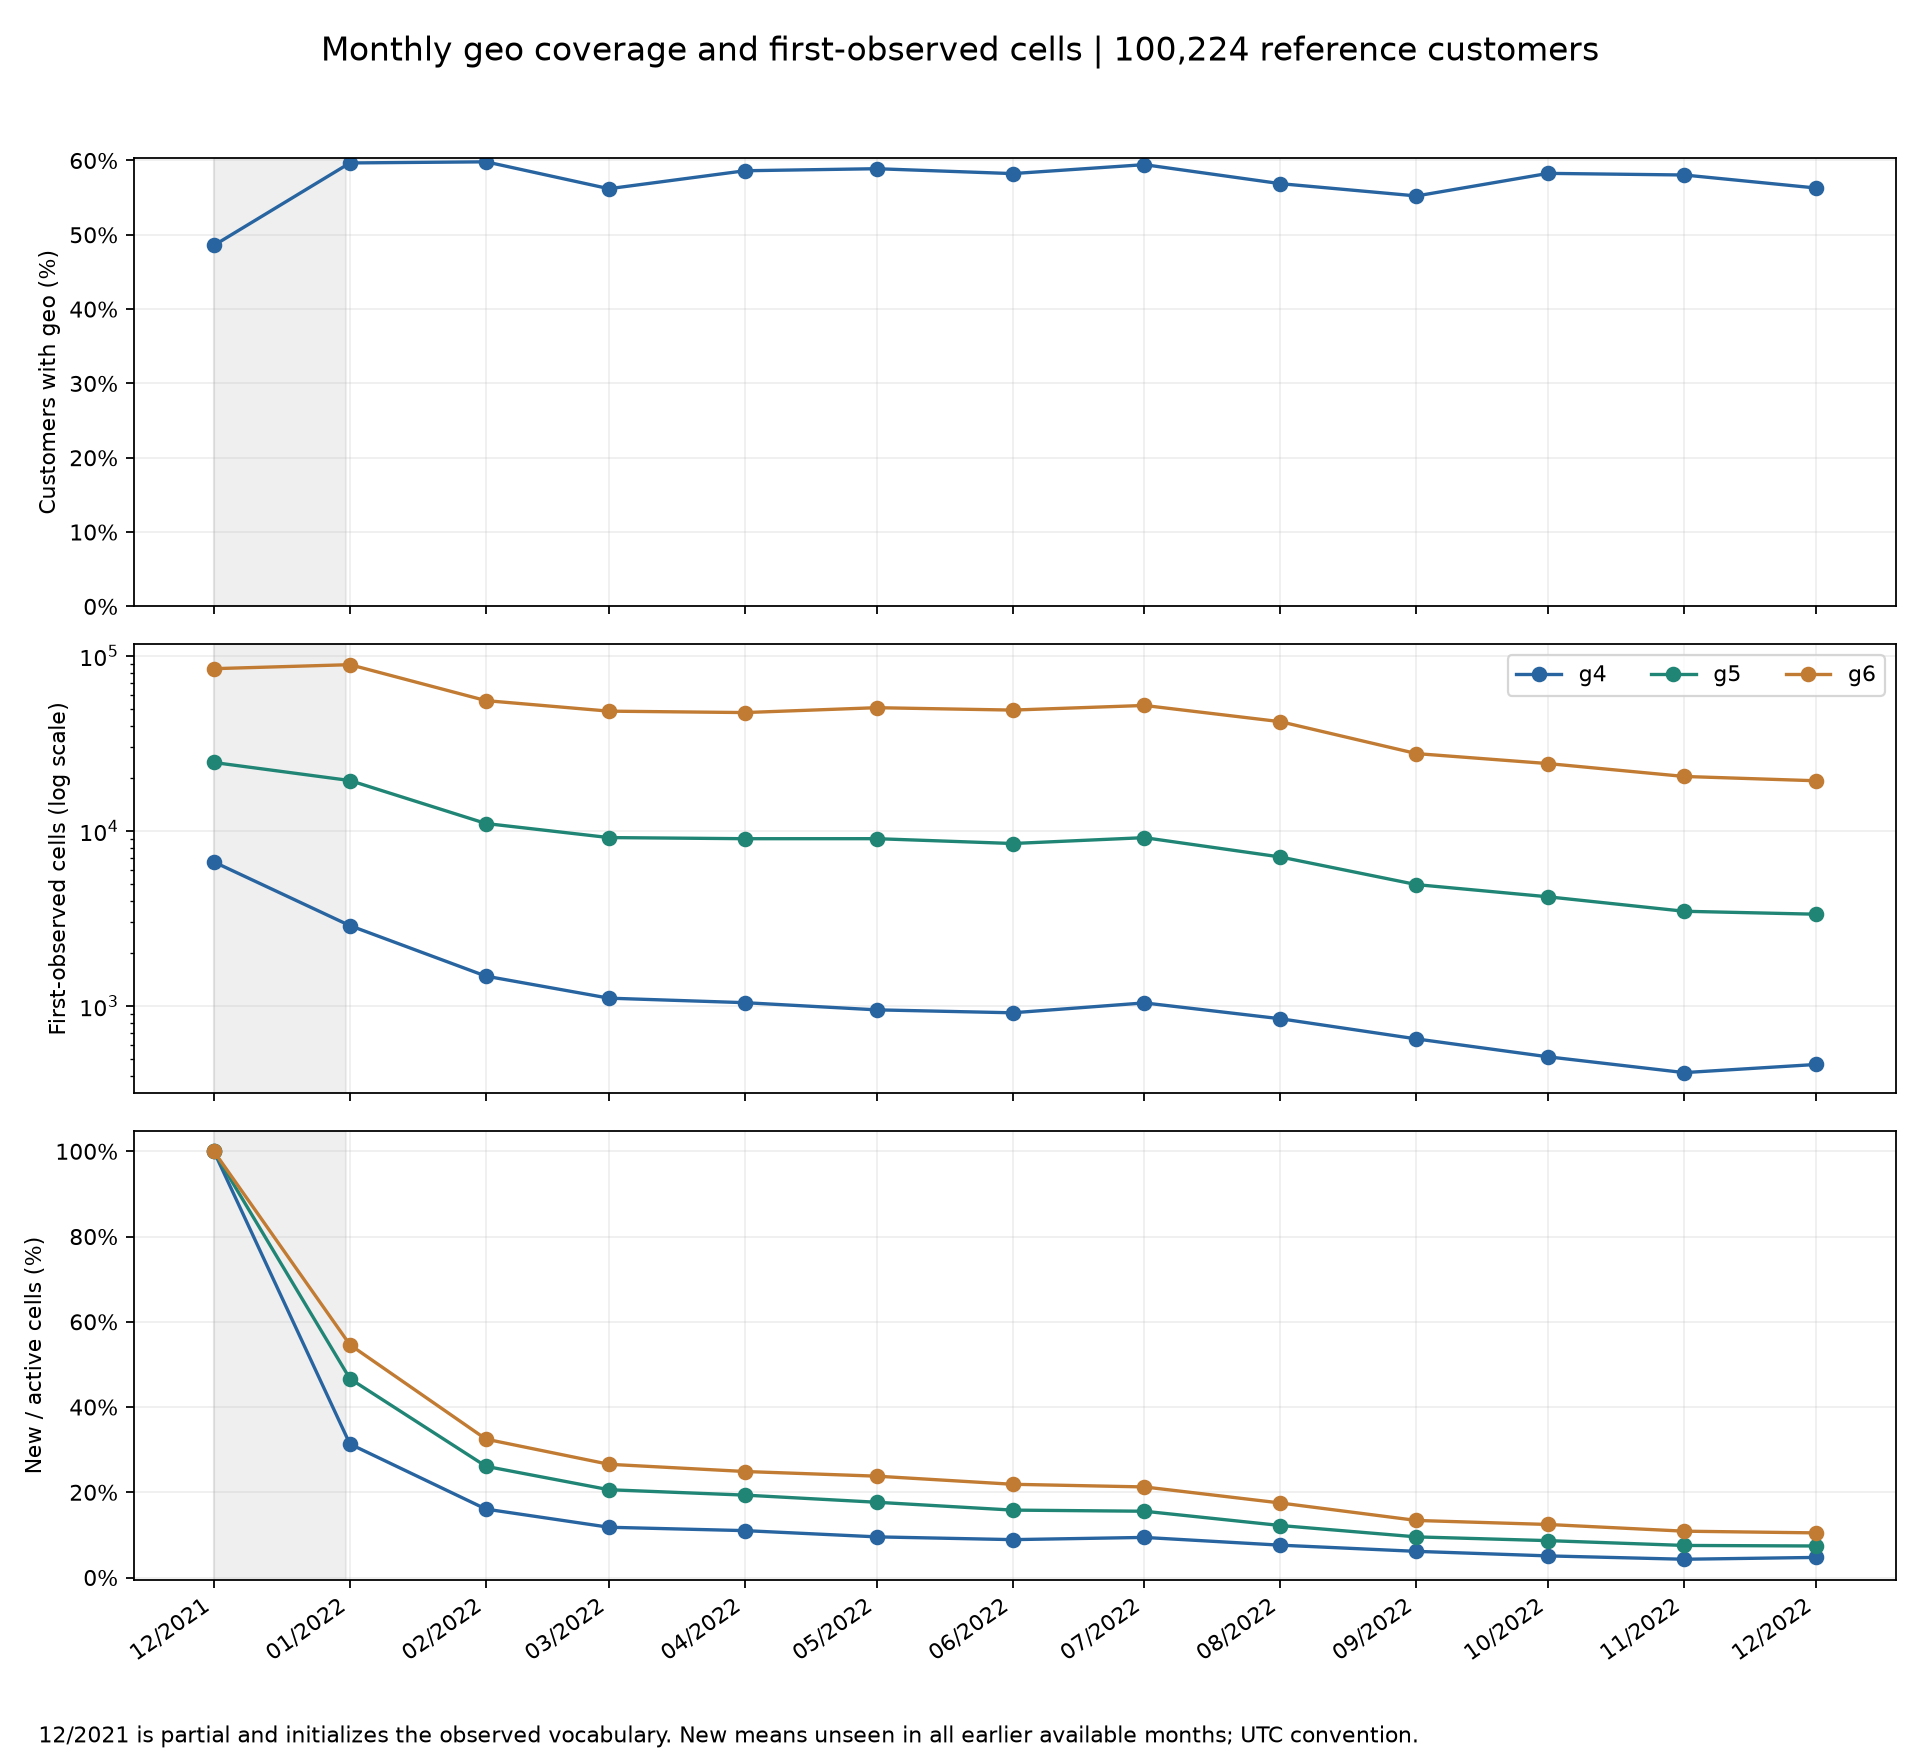

**outputs/geo_temporal_coverage/monthly_cells.csv** — 5 dòng đầu

,month,active_cells,new_cells,events_in_new_cells,retained_from_previous,level,new_pct,cumulative_seen,new_cell_event_pct,previous_month_cells,previous_month_retention_pct,jaccard_previous_pct
0,2021-12-01,6650,6650,731236.0,0,g4,100.000000,6650,100.000000,NaN,NaN,NaN
1,2022-01-01,9186,2877,11589.0,6309,g4,31.319399,9527,0.268182,6650.0,94.872180,66.222316
2,2022-02-01,9223,1480,4751.0,7631,g4,16.046839,11007,0.090266,9186.0,83.072066,70.801633
3,2022-03-01,9395,1108,2859.0,7808,g4,11.793507,12115,0.046097,9223.0,84.657920,72.229417
4,2022-04-01,9492,1044,3011.0,7763,g4,10.998736,13159,0.055077,9395.0,82.629058,69.786048


**outputs/geo_temporal_coverage/monthly_coverage.csv** — 5 dòng đầu

,month,events,active_clients,observed_days,first_event,last_event,reference_clients,coverage_pct,events_per_active_client
0,2021-12-01,731236,48685,21,2021-12-11 19:27:07.507106,2021-12-31 23:59:45.338665,100224,48.576189,15.019739
1,2022-01-01,4321314,59804,31,2022-01-01 00:00:00.984806,2022-01-31 23:59:52.232882,100224,59.670338,72.257943
2,2022-02-01,5263341,59955,28,2022-02-01 00:00:02.940041,2022-02-28 23:59:55.726810,100224,59.821001,87.788191
3,2022-03-01,6202143,56329,31,2022-03-01 00:00:01.078537,2022-03-31 23:59:58.477251,100224,56.203105,110.105683
4,2022-04-01,5466890,58751,30,2022-04-01 00:00:02.872885,2022-04-30 23:59:58.088828,100224,58.619692,93.051863


In [10]:
show_generated_results(__eda_started_ns, 'src/scripts/analyze_geo_temporal_coverage.py')

## Analyze Geo Calendar Patterns

Nguồn: `src/scripts/analyze_geo_calendar_patterns.py`. Chạy các ô của phần này theo thứ tự.

In [11]:
__file__ = str(ROOT / 'src/scripts/analyze_geo_calendar_patterns.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [12]:
"""Calendar exposure-normalized raw GEO patterns using project UTC convention."""
from pathlib import Path
import duckdb
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

out=Path('outputs/geo_calendar_patterns')
out.mkdir(parents=True,exist_ok=True)
c=duckdb.connect()
c.execute('SET threads=4')
c.execute("SET memory_limit='4GB'")
c.execute("SET temp_directory='outputs/geo_calendar_patterns/duckdb_tmp'")
# Complete calendar months only; exclude partial December 2021.
c.execute("CREATE VIEW geo AS SELECT * FROM read_parquet('data/MBD-mini/detail/geo/**/*.parquet') WHERE event_time>=TIMESTAMP '2022-01-01' AND event_time<TIMESTAMP '2023-01-01'")
hourly=c.execute('''SELECT cast(event_time AS DATE) AS day,extract(hour FROM event_time)::INT AS hour,
 count(*) events,count(distinct client_id) customers FROM geo GROUP BY 1,2''').df()
hourly.day=pd.to_datetime(hourly.day)
calendar=pd.DataFrame({'day':pd.date_range('2022-01-01','2022-12-31')})
grid=calendar.merge(pd.DataFrame({'hour':range(24)}),how='cross').merge(hourly,how='left',on=['day','hour']).fillna({'events':0,'customers':0})
grid['weekday']=grid.day.dt.dayofweek
grid['dom']=grid.day.dt.day
grid['days_to_month_end']=grid.day.dt.days_in_month-grid.dom
grid.to_csv(out/'daily_hourly_counts.csv',index=False)
wh=grid.groupby(['weekday','hour']).agg(mean_events=('events','mean'),mean_customers=('customers','mean'),observed_days=('day','size')).reset_index()
wh.to_csv(out/'weekday_hour.csv',index=False)
daily=c.execute('''SELECT cast(event_time AS DATE) AS day,count(*) events,count(distinct client_id) customers FROM geo GROUP BY 1''').df()
daily.day=pd.to_datetime(daily.day)
daily=calendar.merge(daily,how='left',on='day').fillna({'events':0,'customers':0})
daily['dom']=daily.day.dt.day
daily['days_to_month_end']=daily.day.dt.days_in_month-daily.dom
daily['weekday']=daily.day.dt.dayofweek
# Relative-to-month average removes differing monthly source volume.
daily['month']=daily.day.dt.to_period('M').astype(str)
for metric in ['events','customers']:
    daily[f'{metric}_month_index']=daily[metric]/daily.groupby('month')[metric].transform('mean')
daily.to_csv(out/'daily_counts.csv',index=False)
for col in ['dom','days_to_month_end']:
    agg=daily.groupby(col).agg(observed_days=('day','size'),mean_events=('events','mean'),mean_customers=('customers','mean'),events_month_index=('events_month_index','mean'),customers_month_index=('customers_month_index','mean')).reset_index()
    agg.to_csv(out/f'{col}_summary.csv',index=False)
dom=pd.read_csv(out/'dom_summary.csv')
fig,axes=plt.subplots(2,2,figsize=(15,10),dpi=170)
for ax,metric,title in zip(axes[0],['mean_events','mean_customers'],['GEO events / calendar hour','Distinct customers / calendar hour']):
    mat=wh.pivot(index='weekday',columns='hour',values=metric)
    im=ax.imshow(mat,aspect='auto',cmap='YlGnBu')
    ax.set_yticks(range(7),['Mon','Tue','Wed','Thu','Fri','Sat','Sun'])
    ax.set_xticks(range(0,24,2))
    ax.set_xlabel('Hour (UTC)')
    ax.set_title(title)
    fig.colorbar(im,ax=ax,shrink=.8)
for metric,color,label in [('events','#2864a0','Events'),('customers','#208575','Distinct customers')]:
    # Normalize means across all calendar days, not across DOM groups.
    axes[1,0].plot(dom.dom,dom[f'mean_{metric}']/daily[metric].mean(),marker='o',ms=3,color=color,label=label)
    end=pd.read_csv(out/'days_to_month_end_summary.csv').query('days_to_month_end<=9')
    axes[1,1].plot(end.days_to_month_end,end[f'mean_{metric}']/daily[metric].mean(),marker='o',color=color,label=label)
axes[1,0].set_xlabel('Day of month')
axes[1,0].set_xticks([1,5,10,15,20,25,28,29,30,31])
axes[1,0].set_title('Mean per observed calendar day / annual daily mean')
axes[1,1].set_xlabel('Days before month end (0 = last day)')
axes[1,1].invert_xaxis()
axes[1,1].set_title('Month-end alignment')
for ax in axes[1]:
    ax.axhline(1,color='grey',ls='--',lw=1)
    ax.set_ylabel('Relative daily activity')
    ax.grid(alpha=.2)
    ax.legend()
fig.suptitle('GEO calendar patterns | Jan–Dec 2022 | UTC convention',fontsize=19)
fig.tight_layout(rect=(0,.045,1,.95))
fig.text(.02,.015,'Heatmaps average over calendar occurrences. Day 31 has 7 observations; day 30: 11; day 29: 11; others: 12. No session inference.',fontsize=10)
fig.savefig(out/'geo_calendar_patterns.png')
assert daily.events.sum()==65564488
assert len(grid)==365*24 and len(daily)==365
print('Total events:',int(daily.events.sum()))
for metric in ['mean_events','mean_customers']:
    print('Peak weekday-hour',metric,wh.nlargest(3,metric).to_string(index=False))
print('Day-of-month:',dom.to_string(index=False))
print('Weekday mean:',daily.groupby('weekday')[['events','customers']].mean().to_string())

C:\Users\admin\AppData\Local\Temp\ipykernel_7208\3110004255.py:23: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  grid['weekday']=grid.day.dt.dayofweek


C:\Users\admin\AppData\Local\Temp\ipykernel_7208\3110004255.py:34: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  daily['weekday']=daily.day.dt.dayofweek


Total events: 65564488
Peak weekday-hour mean_events  weekday  hour  mean_events  mean_customers  observed_days
       4    10 13148.230769     9869.230769             52
       6    10 13145.673077     9851.519231             52
       3    10 13125.557692     9850.442308             52
Peak weekday-hour mean_customers  weekday  hour  mean_events  mean_customers  observed_days
       4    10 13148.230769     9869.230769             52
       6     9 13116.230769     9855.653846             52
       6    10 13145.673077     9851.519231             52
Day-of-month:  dom  observed_days   mean_events  mean_customers  events_month_index  customers_month_index
   1             12 174673.583333    38605.666667            0.965140               0.984288
   2             12 175026.250000    38646.166667            0.967471               0.985348
   3             12 174828.916667    38637.166667            0.966625               0.985160
   4             12 175059.833333    38644.166667       

### Kết quả: `src/scripts/analyze_geo_calendar_patterns.py`

**outputs/geo_calendar_patterns/geo_calendar_patterns.png**

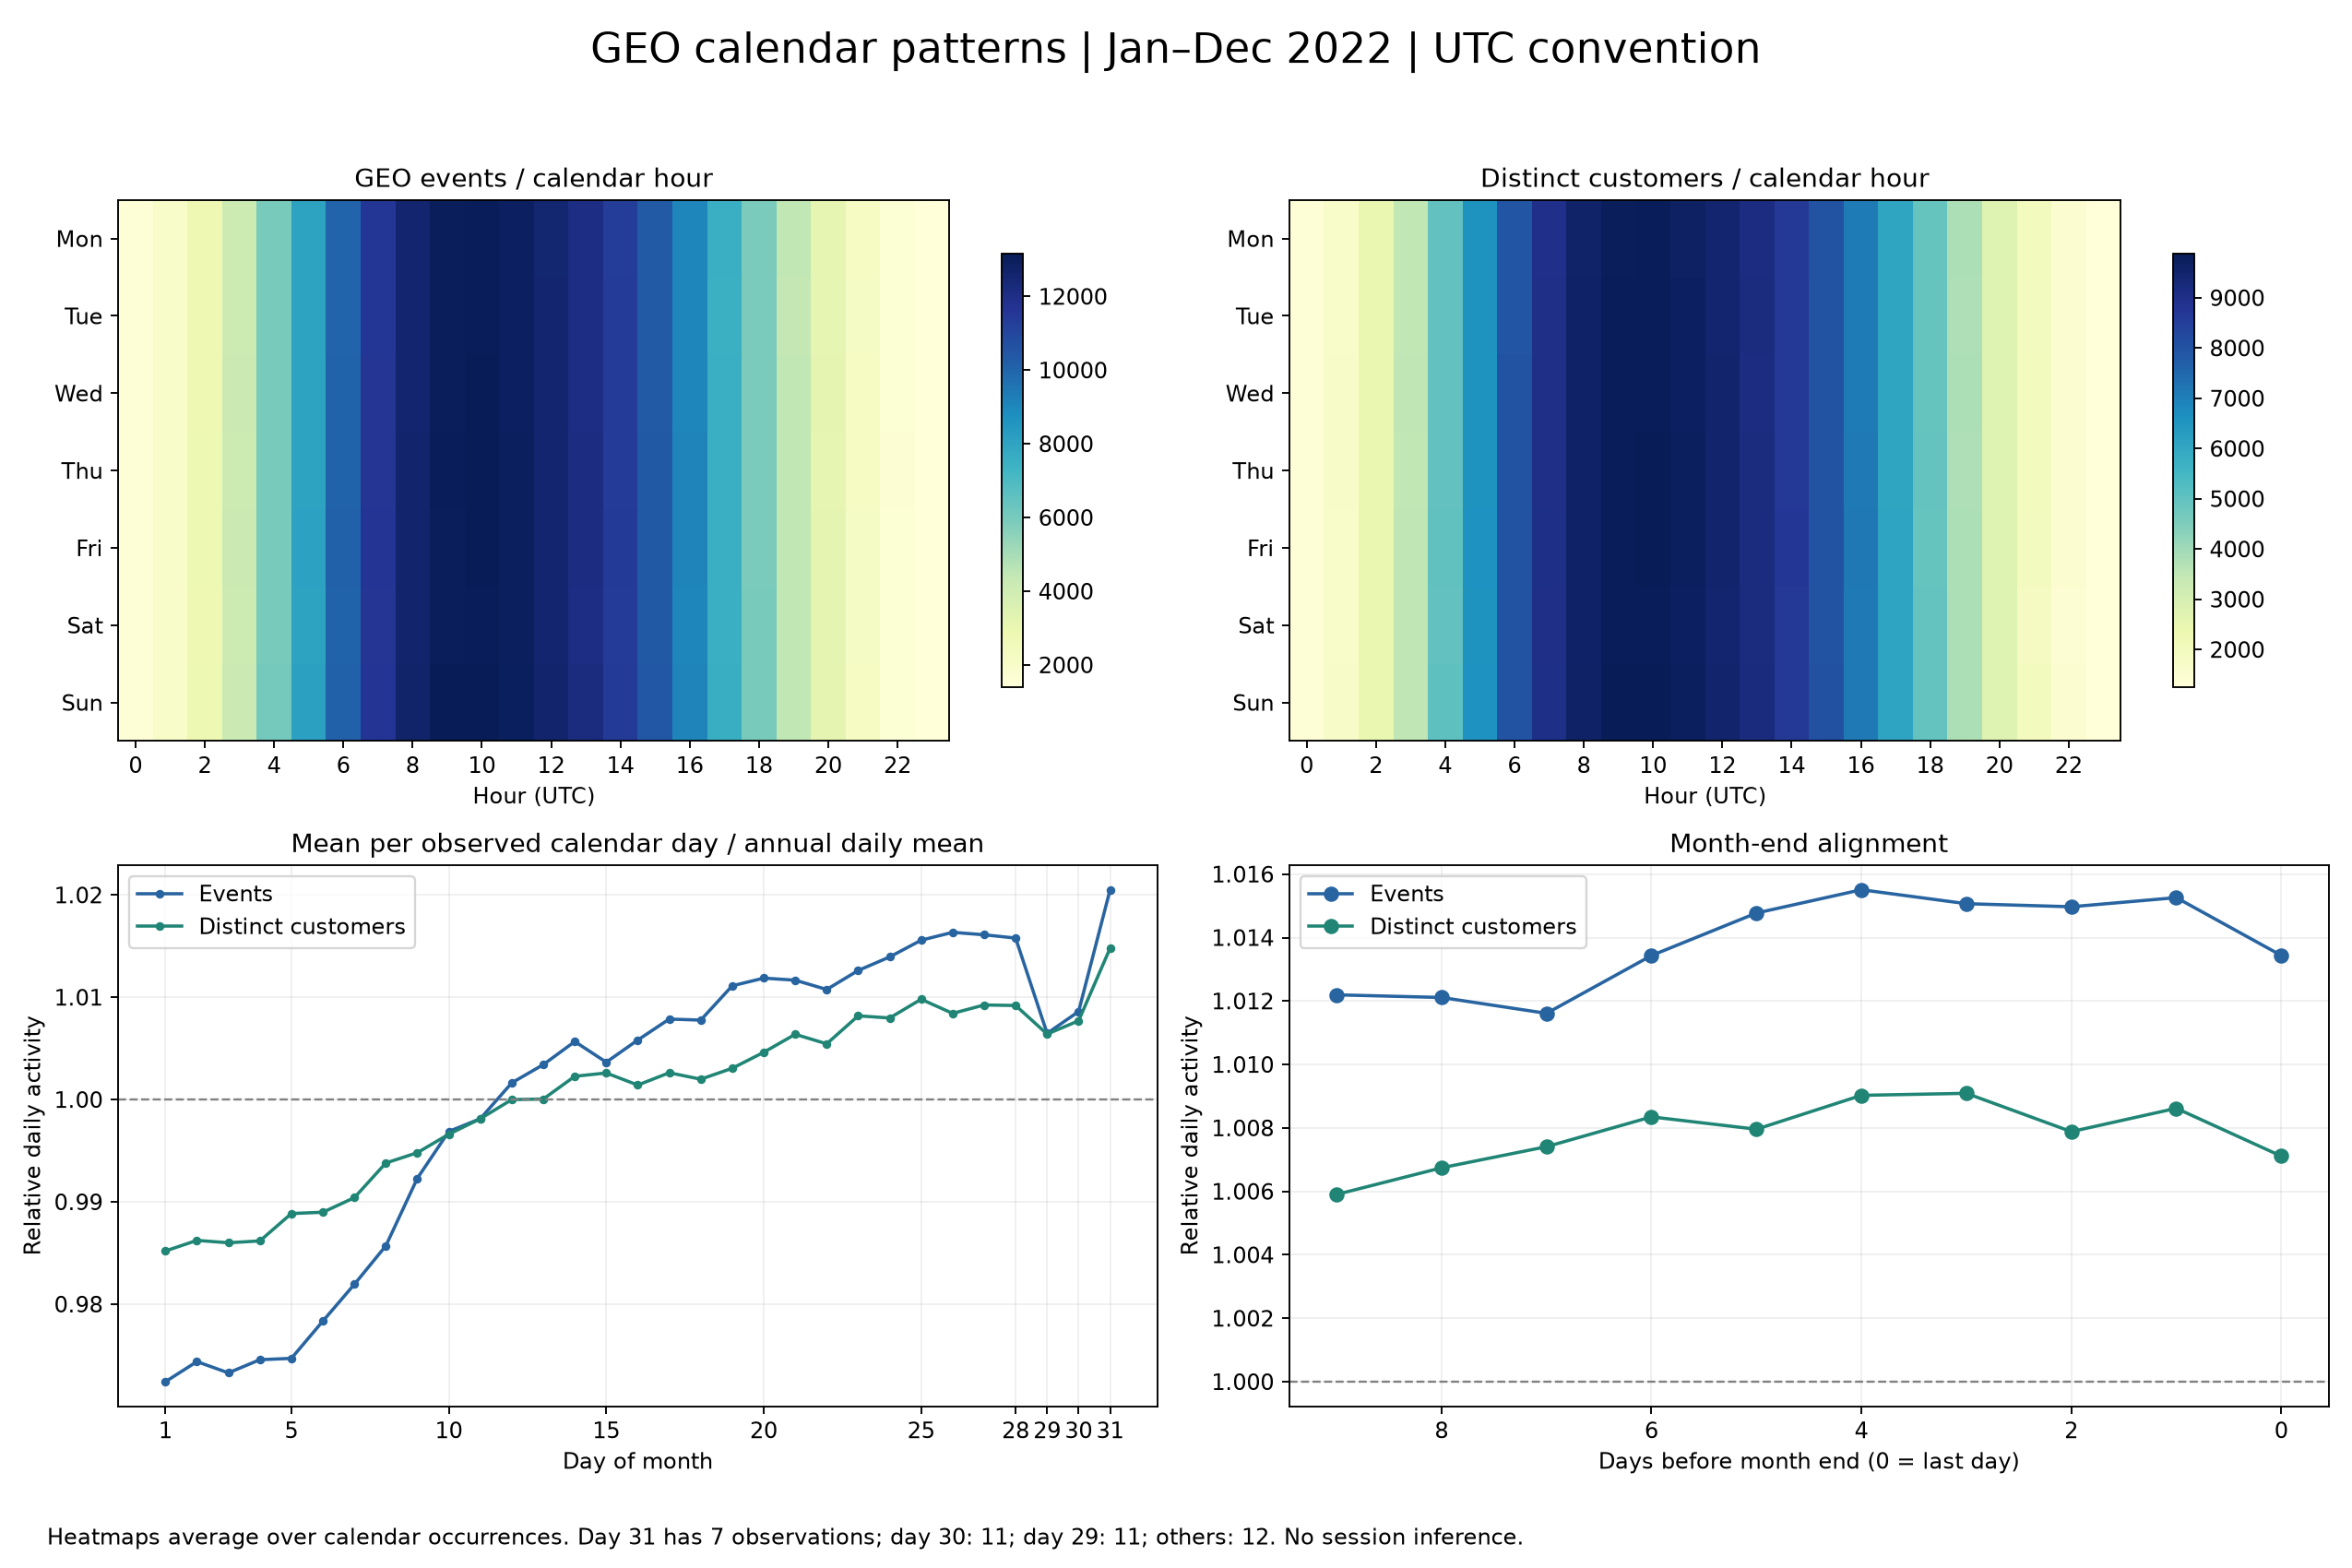

**outputs/geo_calendar_patterns/daily_counts.csv** — 5 dòng đầu

,day,events,customers,dom,days_to_month_end,weekday,month,events_month_index,customers_month_index
0,2022-01-01,81587,29557,1,30,5,2022-01,0.585284,0.793361
1,2022-01-02,85279,29986,2,29,6,2022-01,0.611770,0.804876
2,2022-01-03,88075,30594,3,28,0,2022-01,0.631827,0.821196
3,2022-01-04,92813,31338,4,27,1,2022-01,0.665817,0.841166
4,2022-01-05,96965,32154,5,26,2,2022-01,0.695602,0.863069


**outputs/geo_calendar_patterns/daily_hourly_counts.csv** — 5 dòng đầu

,day,hour,events,customers,weekday,dom,days_to_month_end
0,2022-01-01,0,768.0,720.0,5,1,30
1,2022-01-01,1,867.0,797.0,5,1,30
2,2022-01-01,2,1189.0,1100.0,5,1,30
3,2022-01-01,3,1677.0,1546.0,5,1,30
4,2022-01-01,4,2431.0,2191.0,5,1,30


**outputs/geo_calendar_patterns/days_to_month_end_summary.csv** — 5 dòng đầu

,days_to_month_end,observed_days,mean_events,mean_customers,events_month_index,customers_month_index
0,0,12,182042.333333,39464.416667,1.018909,1.007612
1,1,12,182369.750000,39523.500000,1.021068,1.009148
2,2,12,182318.000000,39494.666667,1.020566,1.008429
3,3,12,182335.416667,39542.000000,1.020183,1.009578
4,4,12,182414.333333,39539.500000,1.019976,1.009456


**outputs/geo_calendar_patterns/dom_summary.csv** — 5 dòng đầu

,dom,observed_days,mean_events,mean_customers,events_month_index,customers_month_index
0,1,12,174673.583333,38605.666667,0.965140,0.984288
1,2,12,175026.250000,38646.166667,0.967471,0.985348
2,3,12,174828.916667,38637.166667,0.966625,0.985160
3,4,12,175059.833333,38644.166667,0.968384,0.985374
4,5,12,175083.250000,38749.083333,0.968892,0.988129


**outputs/geo_calendar_patterns/weekday_hour.csv** — 5 dòng đầu

,weekday,hour,mean_events,mean_customers,observed_days
0,0,0,1552.961538,1363.307692,52
1,0,1,1984.307692,1715.673077,52
2,0,2,2811.346154,2406.442308,52
3,0,3,4141.961538,3508.846154,52
4,0,4,5971.307692,4978.846154,52


File kết quả khác: `outputs/geo_calendar_patterns/duckdb_tmp/duckdb_temp_7208_0_owner`

In [13]:
show_generated_results(__eda_started_ns, 'src/scripts/analyze_geo_calendar_patterns.py')

## Analyze Geo Frequency Recency

Nguồn: `src/scripts/analyze_geo_frequency_recency.py`. Chạy các ô của phần này theo thứ tự.

In [14]:
__file__ = str(ROOT / 'src/scripts/analyze_geo_frequency_recency.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [15]:
"""Point-in-time geo frequency/active days and full-history recency."""
from pathlib import Path
import duckdb
import pandas as pd

out=Path('outputs/geo_frequency_recency')
out.mkdir(parents=True,exist_ok=True)
c=duckdb.connect()
c.execute('SET threads=4')
c.execute("SET memory_limit='4GB'")
c.execute("CREATE VIEW geo AS SELECT * FROM read_parquet('data/MBD-mini/detail/geo/**/*.parquet')")
c.execute("CREATE TEMP TABLE clients AS SELECT DISTINCT client_id FROM read_parquet('data/MBD-mini/client_split/**/*.parquet')")
c.execute("CREATE TEMP TABLE daily AS SELECT client_id,cast(event_time AS DATE) AS day,count(*) events,max(event_time) last_event FROM geo GROUP BY 1,2")
start=c.execute('SELECT min(day) FROM daily').fetchone()[0]
cutoffs=c.execute("SELECT DISTINCT date_trunc('month',cast(mon AS DATE))::DATE FROM read_parquet('data/MBD-mini/targets/**/*.parquet') ORDER BY 1").fetchall()
files=[]
for (cutoff,) in cutoffs:
    fields=['sum(events) geo_all_events','count(*) geo_all_active_days',
            f"epoch(DATE '{cutoff}' - max(last_event))/86400.0 geo_recency_days"]
    for w in [7,30,90]:
        fields.extend([f"sum(events) FILTER(WHERE day>=DATE '{cutoff}'-INTERVAL '{w} days') geo_{w}d_events",
            f"count(*) FILTER(WHERE day>=DATE '{cutoff}'-INTERVAL '{w} days') geo_{w}d_active_days"])
    c.execute(f"CREATE OR REPLACE TEMP TABLE agg AS SELECT client_id,{','.join(fields)} FROM daily WHERE day<DATE '{cutoff}' GROUP BY client_id")
    cols=["coalesce(geo_all_events,0) geo_all_events","coalesce(geo_all_active_days,0) geo_all_active_days","geo_recency_days", "CAST(geo_recency_days IS NULL AS INTEGER) geo_never_seen_before_cutoff"]
    for w in [7,30,90]:
        cols.extend([f'coalesce(geo_{w}d_events,0) geo_{w}d_events',f'coalesce(geo_{w}d_active_days,0) geo_{w}d_active_days',
            f"DATE '{start}' > DATE '{cutoff}'-INTERVAL '{w} days' geo_{w}d_source_truncated"])
    path=out/f'cutoff_{cutoff}.parquet'
    c.execute(f"COPY (SELECT client_id,DATE '{cutoff}' cutoff,{','.join(cols)} FROM clients LEFT JOIN agg USING(client_id)) TO '{path.as_posix()}' (FORMAT PARQUET)")
    files.append(str(path))
    print(cutoff,flush=True)
df=pd.concat([pd.read_parquet(p) for p in files],ignore_index=True)
rows=[]
metrics=['geo_all_events','geo_all_active_days']+[f'geo_{w}d_{m}' for w in [7,30,90] for m in ['events','active_days']]+['geo_recency_days']
for col in metrics:
    x=df[col].dropna()
    rows.append(dict(feature=col,n=len(x),missing=int(df[col].isna().sum()),zero_pct=(x==0).mean()*100,
        mean=x.mean(),median=x.median(),p90=x.quantile(.9),p99=x.quantile(.99),maximum=x.max()))
pd.DataFrame(rows).to_csv(out/'summary.csv',index=False)
monthly=df.groupby('cutoff').agg(customer_months=('client_id','size'),never_seen=('geo_never_seen_before_cutoff','sum'))
for w in [7,30,90]:
    monthly[f'has_geo_{w}d_pct']=df.groupby('cutoff')[f'geo_{w}d_events'].apply(lambda x:(x>0).mean()*100)
    monthly[f'source_truncated_{w}d']=df.groupby('cutoff')[f'geo_{w}d_source_truncated'].first()
monthly.to_csv(out/'monthly_summary.csv')
assert len(df)==1202688
assert (df.geo_7d_events<=df.geo_30d_events).all() and (df.geo_30d_events<=df.geo_90d_events).all()
assert (df.geo_90d_events<=df.geo_all_events).all()
for w in [7,30,90]:
    assert df[f'geo_{w}d_active_days'].between(0,w).all()
    assert (df[f'geo_{w}d_active_days']<=df[f'geo_{w}d_events']).all()
assert (df.geo_recency_days.dropna()>0).all()
print(pd.DataFrame(rows).to_string(index=False))
print(monthly.to_string())

2022-02-01


2022-03-01


2022-04-01


2022-05-01


2022-06-01


2022-07-01


... (3 outputs left out)

2022-11-01


2022-12-01


2023-01-01


            feature       n  missing  zero_pct       mean    median         p90         p99      maximum
     geo_all_events 1202688        0 32.791880 359.706160 66.000000 1063.000000 3519.000000 39487.000000
geo_all_active_days 1202688        0 32.791880  80.352247 41.000000  234.000000  347.000000   386.000000
      geo_7d_events 1202688        0 47.141570  12.729526  1.000000   40.000000  118.000000  1344.000000
 geo_7d_active_days 1202688        0 47.141570   2.759565  1.000000    7.000000    7.000000     7.000000
     geo_30d_events 1202688        0 42.073672  53.823514  8.000000  165.000000  495.000000  5308.000000
geo_30d_active_days 1202688        0 42.073672  11.739644  7.000000   30.000000   30.000000    30.000000
     geo_90d_events 1202688        0 36.938923 149.000563 28.000000  448.000000 1363.000000 14478.000000
geo_90d_active_days 1202688        0 36.938923  32.803130 21.000000   88.000000   90.000000    90.000000
   geo_recency_days  808304   394384  0.000000  16.1780

In [16]:
show_generated_results(__eda_started_ns, 'src/scripts/analyze_geo_frequency_recency.py')

### Kết quả: `src/scripts/analyze_geo_frequency_recency.py`

**outputs/geo_frequency_recency/monthly_summary.csv** — 5 dòng đầu

,cutoff,customer_months,never_seen,has_geo_7d_pct,source_truncated_7d,has_geo_30d_pct,source_truncated_30d,has_geo_90d_pct,source_truncated_90d
0,2022-02-01,100224,40184,56.142241,False,59.641403,False,59.905811,True
1,2022-03-01,100224,38085,52.470466,False,60.140286,False,62.000120,True
2,2022-04-01,100224,36770,52.047414,False,56.122286,False,63.195442,False
3,2022-05-01,100224,34905,54.616659,False,58.619692,False,64.086446,False
4,2022-06-01,100224,33812,51.982559,False,58.783325,False,62.664631,False


**outputs/geo_frequency_recency/summary.csv** — 5 dòng đầu

,feature,n,missing,zero_pct,mean,median,p90,p99,maximum
0,geo_all_events,1202688,0,32.791880,359.706160,66.0,1063.0,3519.0,39487.0
1,geo_all_active_days,1202688,0,32.791880,80.352247,41.0,234.0,347.0,386.0
2,geo_7d_events,1202688,0,47.141570,12.729526,1.0,40.0,118.0,1344.0
3,geo_7d_active_days,1202688,0,47.141570,2.759565,1.0,7.0,7.0,7.0
4,geo_30d_events,1202688,0,42.073672,53.823514,8.0,165.0,495.0,5308.0


File kết quả khác: `outputs/geo_frequency_recency/cutoff_2022-02-01.parquet`, `outputs/geo_frequency_recency/cutoff_2022-03-01.parquet`, `outputs/geo_frequency_recency/cutoff_2022-04-01.parquet`, `outputs/geo_frequency_recency/cutoff_2022-05-01.parquet`, `outputs/geo_frequency_recency/cutoff_2022-06-01.parquet`, `outputs/geo_frequency_recency/cutoff_2022-07-01.parquet`, `outputs/geo_frequency_recency/cutoff_2022-08-01.parquet`, `outputs/geo_frequency_recency/cutoff_2022-09-01.parquet`, `outputs/geo_frequency_recency/cutoff_2022-10-01.parquet`, `outputs/geo_frequency_recency/cutoff_2022-11-01.parquet`, `outputs/geo_frequency_recency/cutoff_2022-12-01.parquet`, `outputs/geo_frequency_recency/cutoff_2023-01-01.parquet`

## Analyze Geo Frequency Deciles

Nguồn: `src/scripts/analyze_geo_frequency_deciles.py`. Chạy các ô của phần này theo thứ tự.

In [17]:
__file__ = str(ROOT / 'src/scripts/analyze_geo_frequency_deciles.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [18]:
"""Purchase rates by descriptive GEO event-count decile within each cutoff."""
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

OUT=Path('outputs/geo_frequency_deciles')
OUT.mkdir(parents=True,exist_ok=True)
df=pd.read_parquet('outputs/geo_trend_purchase/customer_month_trend_labels.parquet')
assert len(df)==1002240 and not df.geo_30d_source_truncated.any()
df['decile']=0
edges=[]
for cutoff,part in df.groupby('cutoff'):
    positive=part.index[part.geo_30d_events>0]
    bins,bounds=pd.qcut(df.loc[positive,'geo_30d_events'],10,labels=False,retbins=True,duplicates='raise')
    df.loc[positive,'decile']=bins+1
    for i in range(10):
        edges.append(dict(cutoff=cutoff,decile=i+1,lower_edge=bounds[i],upper_edge=bounds[i+1],lower_inclusive=i==0))
pd.DataFrame(edges).to_csv(OUT/'decile_edges_by_cutoff.csv',index=False)
df[['client_id','cutoff','geo_30d_events','decile','y_1','y_2','y_3']].to_parquet(OUT/'customer_month_deciles.parquet',index=False)
tables=[];monthly=[]
for h in [1,2,3]:
    y=f'y_{h}'
    t=df.groupby('decile').agg(customer_months=('client_id','size'),buyers=(y,'sum'),purchase_rate=(y,'mean'),
        min_events=('geo_30d_events','min'),median_events=('geo_30d_events','median'),max_events=('geo_30d_events','max')).reset_index()
    t['horizon']=h
    t['baseline_all']=df[y].mean()
    t['baseline_geo_positive']=df.loc[df.decile>0,y].mean()
    t['lift_all']=t.purchase_rate/t.baseline_all
    t['lift_geo_positive']=t.purchase_rate/t.baseline_geo_positive
    tables.append(t)
    m=df.groupby(['cutoff','decile']).agg(customer_months=('client_id','size'),buyers=(y,'sum'),purchase_rate=(y,'mean')).reset_index()
    m['horizon']=h
    monthly.append(m)
t=pd.concat(tables,ignore_index=True)
t.to_csv(OUT/'decile_purchase_rates.csv',index=False)
m=pd.concat(monthly,ignore_index=True)
m.to_csv(OUT/'monthly_decile_purchase_rates.csv',index=False)
fig,ax=plt.subplots(figsize=(12,6.7),dpi=180)
colors=['#2864a0','#208575','#c17b33']
for h,color in zip([1,2,3],colors):
    d=t[t.horizon==h]
    ax.plot(d.decile,d.purchase_rate,marker='o',color=color,label=f'{h} month(s)')
    ax.axhline(d.baseline_all.iloc[0],color=color,ls='--',lw=.8,alpha=.65)
ax.set_xticks(range(11),['No GEO\n30d']+[f'D{i}' for i in range(1,11)])
ax.yaxis.set_major_formatter(PercentFormatter(1,decimals=1))
ax.set_ylabel('Cumulative any-product purchase rate')
ax.set_xlabel('30-day GEO event-count decile (D1 = lowest positive, D10 = highest)')
ax.set_ylim(bottom=0);ax.grid(axis='y',alpha=.2);ax.legend(title='Future label horizon')
fig.suptitle('Purchase rate by GEO frequency decile',fontsize=20)
ax.set_title('Common cohort: 1,002,240 customer-months | Feb–Nov 2022 cutoffs',fontsize=11,pad=15)
fig.tight_layout(rect=(0,.08,1,.93))
fig.text(.04,.025,'Deciles within each cutoff among GEO-positive customers; ties kept together. Dashed lines: all-cohort baselines. Descriptive association.',fontsize=10)
fig.savefig(OUT/'geo_decile_purchase.png')
assert (df.loc[df.geo_30d_events.eq(0),'decile']==0).all()
for h in [1,2,3]:
    z=t[t.horizon==h]
    assert z.customer_months.sum()==len(df) and z.buyers.sum()==df[f'y_{h}'].sum()
print(t[t.horizon==1][['decile','customer_months','median_events']].to_string(index=False))
print(t.pivot(index='decile',columns='horizon',values='purchase_rate').to_string())
print(t[t.decile==10][['horizon','purchase_rate','baseline_all','baseline_geo_positive','lift_all','lift_geo_positive']].to_string(index=False))
print('D10 vs D1 monthly direction:',m[m.decile.isin([1,10])].pivot(index=['horizon','cutoff'],columns='decile',values='purchase_rate').groupby(level=0).apply(lambda x:int((x[10]>x[1]).sum())).to_dict())

 decile  customer_months  median_events
      0           419879            0.0
      1            63739            3.0
      2            56496            9.0
      3            56883           17.0
      4            58844           27.0
      5            56485           38.0
      6            57982           55.0
      7            58020           81.0
      8            58094          120.0
      9            57826          185.0
     10            57992          335.0
horizon         1         2         3
decile                               
0        0.009486  0.018115  0.025776
1        0.010935  0.021463  0.030233
2        0.011257  0.022055  0.030816
3        0.011831  0.021729  0.030712
4        0.011352  0.022058  0.031405
5        0.012711  0.023511  0.033867
6        0.012556  0.024232  0.033735
7        0.013220  0.024681  0.034798
8        0.013289  0.024719  0.035408
9        0.014734  0.028361  0.039256
10       0.015968  0.029970  0.042213
 horizon  purchase_rate  b

### Kết quả: `src/scripts/analyze_geo_frequency_deciles.py`

**outputs/geo_frequency_deciles/geo_decile_purchase.png**

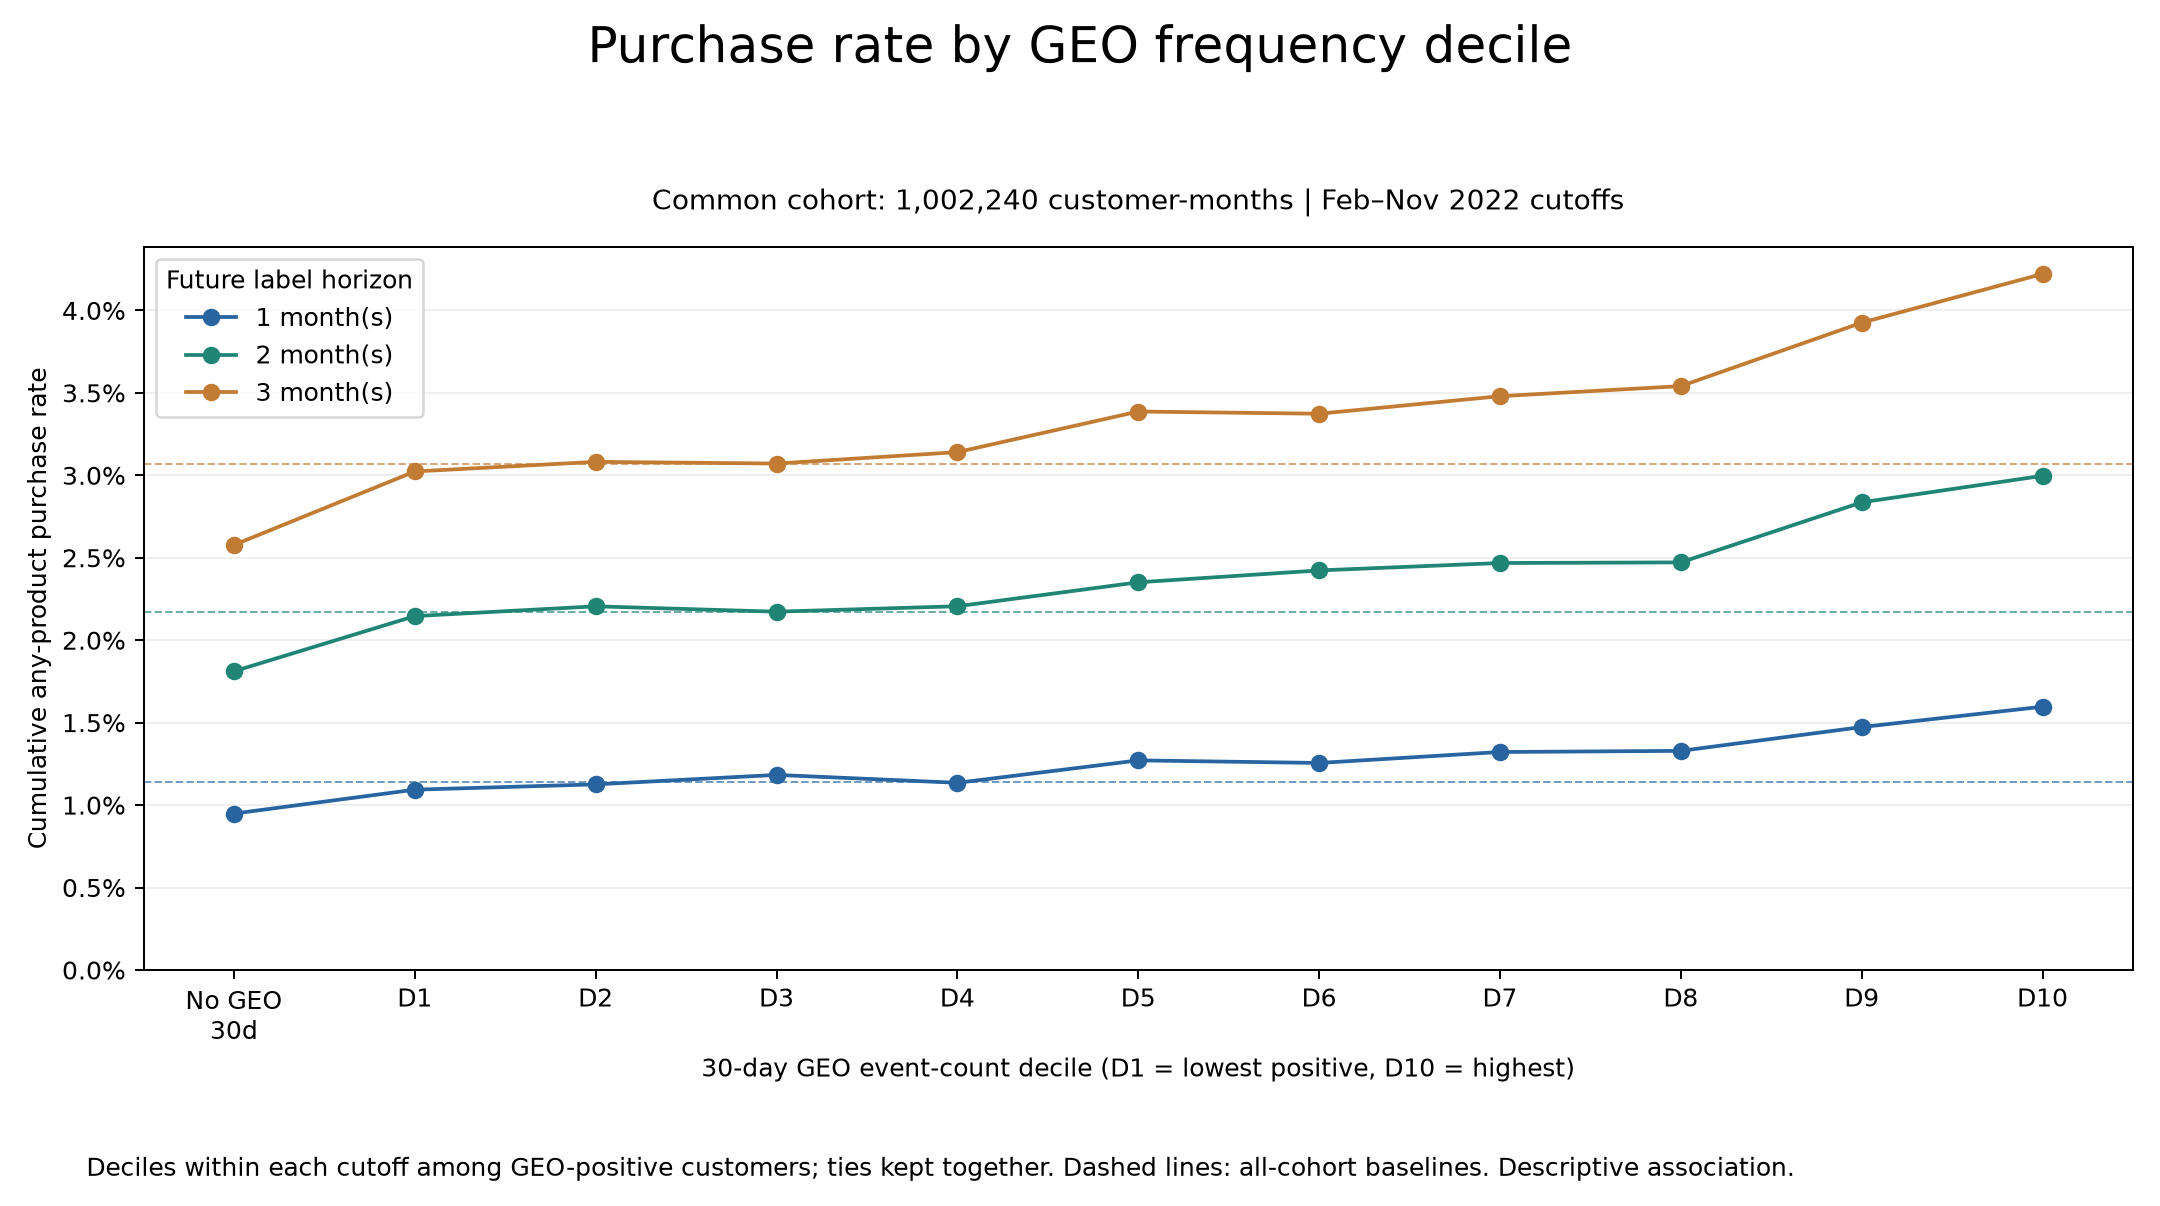

**outputs/geo_frequency_deciles/decile_edges_by_cutoff.csv** — 5 dòng đầu

,cutoff,decile,lower_edge,upper_edge,lower_inclusive
0,2022-02-01,1,1.0,5.0,True
1,2022-02-01,2,5.0,11.0,False
2,2022-02-01,3,11.0,17.0,False
3,2022-02-01,4,17.0,25.0,False
4,2022-02-01,5,25.0,36.0,False


**outputs/geo_frequency_deciles/decile_purchase_rates.csv** — 5 dòng đầu

,decile,customer_months,buyers,purchase_rate,min_events,median_events,max_events,horizon,baseline_all,baseline_geo_positive,lift_all,lift_geo_positive
0,0,419879,3983,0.009486,0.0,0.0,0.0,1,0.011394,0.01277,0.832514,0.742815
1,1,63739,697,0.010935,1.0,3.0,7.0,1,0.011394,0.01277,0.959695,0.856292
2,2,56496,636,0.011257,5.0,9.0,15.0,1,0.011394,0.01277,0.987973,0.881524
3,3,56883,673,0.011831,12.0,17.0,26.0,1,0.011394,0.01277,1.038337,0.926461
4,4,58844,668,0.011352,18.0,27.0,40.0,1,0.011394,0.01277,0.996277,0.888932


**outputs/geo_frequency_deciles/monthly_decile_purchase_rates.csv** — 5 dòng đầu

,cutoff,decile,customer_months,buyers,purchase_rate,horizon
0,2022-02-01,0,40449,335,0.008282,1
1,2022-02-01,1,6772,69,0.010189,1
2,2022-02-01,2,6045,63,0.010422,1
3,2022-02-01,3,5361,55,0.010259,1
4,2022-02-01,4,6027,57,0.009457,1


File kết quả khác: `outputs/geo_frequency_deciles/customer_month_deciles.parquet`

In [19]:
show_generated_results(__eda_started_ns, 'src/scripts/analyze_geo_frequency_deciles.py')

## Analyze Geo Interarrival

Nguồn: `src/scripts/analyze_geo_interarrival.py`. Chạy các ô của phần này theo thứ tự.

In [20]:
__file__ = str(ROOT / 'src/scripts/analyze_geo_interarrival.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [21]:
"""Full-source descriptive interarrival times, not cutoff-specific model features."""
from pathlib import Path
import duckdb
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

out=Path('outputs/geo_interarrival')
out.mkdir(parents=True,exist_ok=True)
c=duckdb.connect()
c.execute('SET threads=2')
c.execute('SET preserve_insertion_order=false')
c.execute("SET memory_limit='4GB'")
c.execute("SET temp_directory='outputs/geo_interarrival/duckdb_tmp'")
c.execute("CREATE VIEW geo AS SELECT client_id,event_time FROM read_parquet('data/MBD-mini/detail/geo/**/*.parquet')")
q='''WITH ordered AS (
 SELECT client_id,event_time,lag(event_time) OVER(PARTITION BY client_id ORDER BY event_time) prev FROM geo
), gaps AS (
 SELECT client_id,epoch(event_time-prev)/3600.0 gap_hours FROM ordered
)
SELECT client_id,count(*) events,count(gap_hours) gaps,
 count(*) FILTER(WHERE gap_hours=0) zero_gaps,
 avg(gap_hours) mean_gap_hours,median(gap_hours) median_gap_hours,
 quantile_cont(gap_hours,.9) p90_gap_hours,max(gap_hours) max_gap_hours,
 stddev_pop(gap_hours) std_gap_hours,
 count(*) FILTER(WHERE gap_hours>0) positive_gaps,
 avg(gap_hours) FILTER(WHERE gap_hours>0) positive_mean_gap_hours,
 median(gap_hours) FILTER(WHERE gap_hours>0) positive_median_gap_hours,
 stddev_pop(gap_hours) FILTER(WHERE gap_hours>0) positive_std_gap_hours
FROM gaps GROUP BY client_id'''
parts=[]
for fold in range(5):
    c.execute(f"CREATE OR REPLACE VIEW geo AS SELECT client_id,event_time FROM read_parquet('data/MBD-mini/detail/geo/fold={fold}/*.parquet')")
    parts.append(c.execute(q).df())
    print(f'event gaps fold {fold} complete',flush=True)
d=pd.concat(parts,ignore_index=True)
assert d.client_id.is_unique
c.execute("CREATE OR REPLACE VIEW geo AS SELECT client_id,event_time FROM read_parquet('data/MBD-mini/detail/geo/**/*.parquet')")
for prefix,n,mean,std in [('', 'gaps','mean_gap_hours','std_gap_hours'),('positive_','positive_gaps','positive_mean_gap_hours','positive_std_gap_hours')]:
    d[prefix+'cv']=np.where((d[n]>=2)&(d[mean]>0),d[std]/d[mean],np.nan)
    d[prefix+'burstiness']=(d[prefix+'cv']-1)/(d[prefix+'cv']+1)
d.to_csv(out/'customer_interarrival.csv',index=False)
print('event gaps complete',flush=True)
day=c.execute('''WITH days AS (SELECT DISTINCT client_id,cast(event_time AS DATE) AS day FROM geo),
 ordered AS (SELECT client_id,day-lag(day) OVER(PARTITION BY client_id ORDER BY day) gap_days FROM days)
 SELECT client_id,count(*) active_days,count(gap_days) day_gaps,avg(gap_days) mean_day_gap,
 median(gap_days) median_day_gap,stddev_pop(gap_days) std_day_gap,
 count(*) FILTER(WHERE gap_days=1) consecutive_day_gaps FROM ordered GROUP BY client_id''').df()
day['day_gap_cv']=np.where(day.day_gaps>=2,day.std_day_gap/day.mean_day_gap,np.nan)
day['consecutive_day_share']=day.consecutive_day_gaps/day.day_gaps.replace(0,np.nan)
day.to_csv(out/'customer_active_day_gaps.csv',index=False)
rows=[]
for frame,cols in [(d,['events','mean_gap_hours','median_gap_hours','p90_gap_hours','max_gap_hours','cv','positive_cv','burstiness']),
                   (day,['active_days','mean_day_gap','day_gap_cv','consecutive_day_share'])]:
    for col in cols:
        x=frame[col].dropna()
        rows.append(dict(metric=col,n=len(x),mean=x.mean(),p10=x.quantile(.1),median=x.median(),p90=x.quantile(.9),p99=x.quantile(.99),maximum=x.max()))
s=pd.DataFrame(rows)
s.to_csv(out/'summary.csv',index=False)
quality=dict(customers=len(d),events=int(d.events.sum()),gaps=int(d.gaps.sum()),zero_gaps=int(d.zero_gaps.sum()),customers_with_zero_gaps=int((d.zero_gaps>0).sum()),customers_one_event=int((d.events==1).sum()),customers_cv_available=int(d.cv.notna().sum()),customers_ge20_gaps=int((d.gaps>=20).sum()))
pd.DataFrame([quality]).to_csv(out/'quality.csv',index=False)
bins=[0,.5,1,2,np.inf]
group=pd.cut(d.cv,bins=bins,right=False).value_counts(sort=False).rename_axis('cv_range').reset_index(name='customers')
group['pct_of_valid_cv']=group.customers/d.cv.notna().sum()*100
group.to_csv(out/'cv_bands.csv',index=False)
stable=d[d.gaps>=20]
stable[['cv','median_gap_hours']].describe(percentiles=[.1,.5,.9,.99]).to_csv(out/'customers_ge20_gaps_summary.csv')
fig,axes=plt.subplots(1,3,figsize=(15,4.8),dpi=170)
for ax,x,label in [(axes[0],d.median_gap_hours,'Median event gap per customer (hours)'),(axes[1],d.cv,'Event-gap CV per customer'),(axes[2],day.consecutive_day_share,'Fraction of day gaps equal to 1 day')]:
    x=x.dropna().to_numpy(); values,freq=np.unique(x,return_counts=True)
    y=np.cumsum(freq)/len(x)
    if ax is not axes[2]:
        valid=values>0; ax.semilogx(values[valid],y[valid],color='#2864a0',lw=2)
    else: ax.plot(values,y,color='#208575',lw=2)
    ax.set_xlabel(label); ax.set_ylabel('Fraction of customers <= x'); ax.grid(alpha=.2)
fig.suptitle('GEO interarrival and regularity | full available history | UTC',fontsize=16)
fig.tight_layout(rect=(0,.07,1,.91))
fig.text(.02,.02,'CV = population standard deviation / mean; requires >=2 gaps and positive mean. Each customer has equal weight.',fontsize=10)
fig.savefig(out/'geo_interarrival.png')
assert quality['events']==66295724 and quality['gaps']==66295724-72573
assert (d.zero_gaps<=d.gaps).all()
assert (d.cv.dropna()>=0).all()
print(quality)
print(s.to_string(index=False))
print(group.to_string(index=False))
print('>=20 gaps CV median:',stable.cv.median())

event gaps fold 0 complete


event gaps fold 1 complete


event gaps fold 2 complete


event gaps fold 3 complete


event gaps fold 4 complete


event gaps complete


{'customers': 72573, 'events': 66295724, 'gaps': 66223151, 'zero_gaps': 0, 'customers_with_zero_gaps': 0, 'customers_one_event': 889, 'customers_cv_available': 71103, 'customers_ge20_gaps': 67289}
               metric     n       mean       p10     median         p90         p99      maximum
               events 72573 913.503975 36.000000 507.000000 2293.000000 5580.280000 39487.000000
       mean_gap_hours 71684  60.732909  3.635568  15.068350  105.161047  839.764462  8652.598928
     median_gap_hours 71684  36.413068  1.330765   6.257346   47.399586  482.568867  8652.598928
        p90_gap_hours 71684 109.756074 10.726526  29.797064  186.330534 1670.645003  8652.598928
        max_gap_hours 71684 865.823385 73.913069 280.427061 2474.752168 5965.970569  8699.606945
                   cv 71103   2.535027  1.101153   1.584348    5.456497   12.540194    35.430034
          positive_cv 71103   2.535027  1.101153   1.584348    5.456497   12.540194    35.430034
           burstiness 71103

### Kết quả: `src/scripts/analyze_geo_interarrival.py`

**outputs/geo_interarrival/geo_interarrival.png**

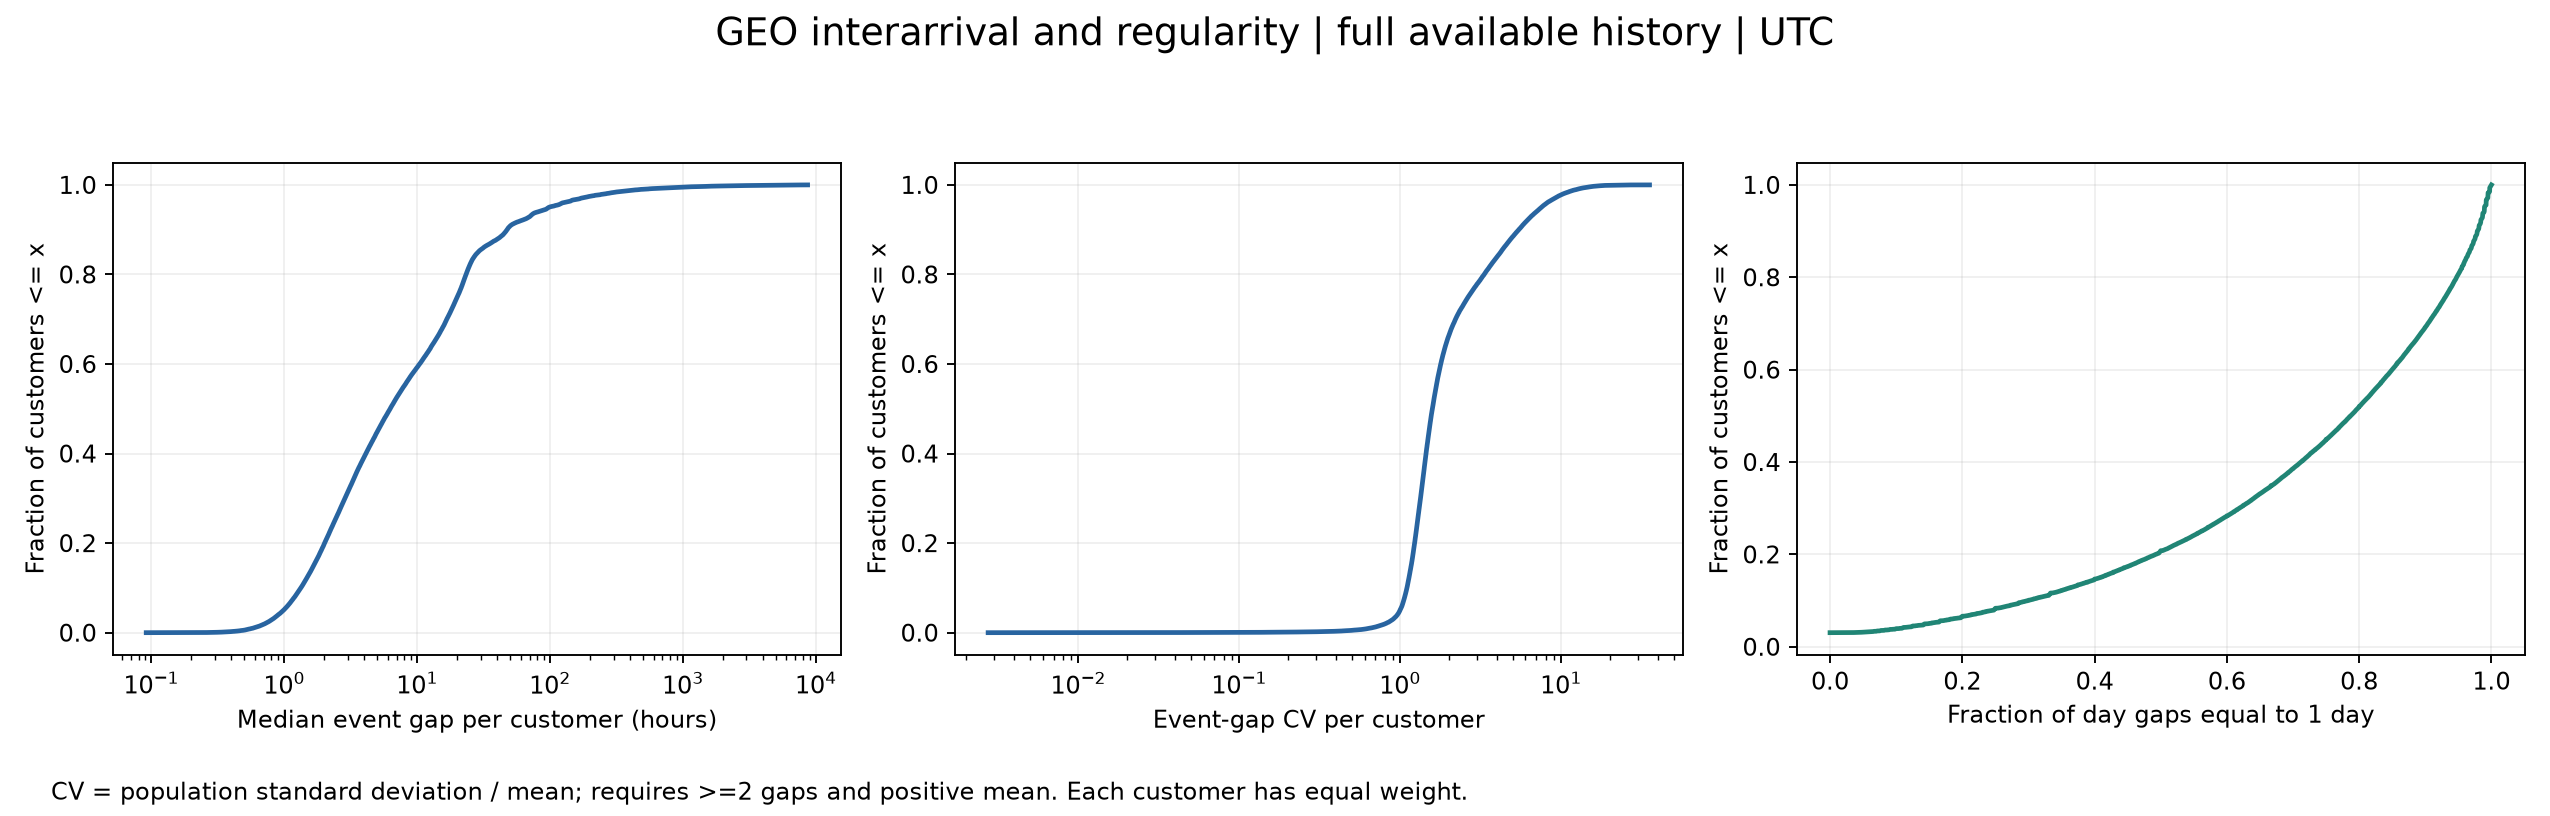

**outputs/geo_interarrival/customer_active_day_gaps.csv** — 5 dòng đầu

,client_id,active_days,day_gaps,mean_day_gap,median_day_gap,std_day_gap,consecutive_day_gaps,day_gap_cv,consecutive_day_share
0,03cc2fbe839ecda63352bff352f149770d357933b22c62...,233,232,1.642241,1.0,1.325002,161,0.806825,0.693966
1,03d4bba4fdeb70397cbbd82208c86ed6bd347d262fa602...,352,351,1.088319,1.0,1.083760,341,0.995811,0.971510
2,04570cffc9967301948609a38c589d05a8d96c9ad7f13b...,341,340,1.102941,1.0,0.431812,314,0.391510,0.923529
3,04cac45b236953d0358e5873b0b6ac19c731ad3b8a0b0d...,231,230,1.500000,1.0,5.698779,214,3.799186,0.930435
4,07220ac733f3c118aef1dc25df79932f08839057c7fb04...,362,361,1.055402,1.0,0.352639,349,0.334128,0.966759


**outputs/geo_interarrival/customer_interarrival.csv** — 5 dòng đầu

,client_id,events,gaps,zero_gaps,mean_gap_hours,median_gap_hours,p90_gap_hours,max_gap_hours,std_gap_hours,positive_gaps,positive_mean_gap_hours,positive_median_gap_hours,positive_std_gap_hours,cv,burstiness,positive_cv,positive_burstiness
0,f557dbf3b45f7b73bface097d9f5c13bd76126fcedb771...,653,652,0,13.142966,5.784235,24.527846,1771.080840,70.074356,652,13.142966,5.784235,70.074356,5.331700,0.684129,5.331700,0.684129
1,f674a5c62b596f741ac4d7839b2c348530ff58b9c311c9...,241,240,0,38.016557,23.492384,89.831057,355.575062,48.557731,240,38.016557,23.492384,48.557731,1.277279,0.121759,1.277279,0.121759
2,02886a76107a463b650f0537834693e390e20313a4c30a...,322,321,0,26.887618,6.833812,47.211415,2132.977569,130.287935,321,26.887618,6.833812,130.287935,4.845648,0.657865,4.845648,0.657865
3,04a3b3f269c3fde4728902eeb46316d513e884d8d4b5cc...,1041,1040,0,8.657861,3.782769,21.071297,191.547749,14.148618,1040,8.657861,3.782769,14.148618,1.634193,0.240754,1.634193,0.240754
4,074a86acad41aec91ff87341ac451ef5d5332129a9d6f1...,19,18,0,418.378613,75.271186,903.388774,3715.943247,866.619619,18,418.378613,75.271186,866.619619,2.071376,0.348826,2.071376,0.348826


**outputs/geo_interarrival/customers_ge20_gaps_summary.csv** — 5 dòng đầu

,Unnamed: 0,cv,median_gap_hours
0,count,67289.000000,67289.000000
1,mean,2.616624,12.967143
2,std,2.440113,20.060322
3,min,0.581782,0.091348
4,10%,1.142364,1.290121


... (2 outputs left out)

**outputs/geo_interarrival/quality.csv** — 5 dòng đầu

,customers,events,gaps,zero_gaps,customers_with_zero_gaps,customers_one_event,customers_cv_available,customers_ge20_gaps
0,72573,66295724,66223151,0,0,889,71103,67289


**outputs/geo_interarrival/summary.csv** — 5 dòng đầu

,metric,n,mean,p10,median,p90,p99,maximum
0,events,72573,913.503975,36.000000,507.000000,2293.000000,5580.280000,39487.000000
1,mean_gap_hours,71684,60.732909,3.635568,15.068350,105.161047,839.764462,8652.598928
2,median_gap_hours,71684,36.413068,1.330765,6.257346,47.399586,482.568867,8652.598928
3,p90_gap_hours,71684,109.756074,10.726526,29.797064,186.330534,1670.645003,8652.598928
4,max_gap_hours,71684,865.823385,73.913069,280.427061,2474.752168,5965.970569,8699.606945


In [22]:
show_generated_results(__eda_started_ns, 'src/scripts/analyze_geo_interarrival.py')

## Analyze Geo Trend Purchase

Nguồn: `src/scripts/analyze_geo_trend_purchase.py`. Chạy các ô của phần này theo thứ tự.

In [23]:
__file__ = str(ROOT / 'src/scripts/analyze_geo_trend_purchase.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [24]:
"""Descriptive point-in-time GEO trend vs complete 1/2/3-month any-product labels."""
from pathlib import Path
import duckdb
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

out=Path('outputs/geo_trend_purchase')
out.mkdir(parents=True,exist_ok=True)
c=duckdb.connect()
c.execute("CREATE TEMP TABLE labels AS SELECT client_id,date_trunc('month',cast(mon AS DATE))::DATE AS cutoff, target_1,target_2,target_3,target_4 FROM read_parquet('data/MBD-mini/targets/**/*.parquet')")
assert c.execute('SELECT count(*) FROM (SELECT client_id,cutoff,count(*) n FROM labels GROUP BY 1,2 HAVING n<>1)').fetchone()[0]==0
assert c.execute('SELECT count(*) FROM labels WHERE target_1 IS NULL OR target_2 IS NULL OR target_3 IS NULL OR target_4 IS NULL').fetchone()[0]==0
labels=c.execute('''WITH monthly AS (SELECT client_id,cutoff,
 greatest(target_1,target_2,target_3,target_4)::INT y FROM labels)
 SELECT a.client_id,a.cutoff,a.y y_1,greatest(a.y,b.y) y_2,greatest(a.y,b.y,d.y) y_3
 FROM monthly a JOIN monthly b ON a.client_id=b.client_id AND b.cutoff=a.cutoff+INTERVAL '1 month'
 JOIN monthly d ON a.client_id=d.client_id AND d.cutoff=a.cutoff+INTERVAL '2 months' ''').df()
features=pd.concat([pd.read_parquet(p) for p in sorted(Path('outputs/geo_frequency_recency').glob('cutoff_*.parquet'))],ignore_index=True)
features.cutoff=pd.to_datetime(features.cutoff)
df=features.merge(labels,on=['client_id','cutoff'],how='inner',validate='one_to_one')
assert len(df)==100224*10
assert not df.geo_30d_source_truncated.any()
df['ratio_7_30']=df.geo_7d_events/df.geo_30d_events.replace(0,np.nan)
df['intensity_index']=df.ratio_7_30*30/7
df['recent_vs_prior23']= (df.geo_7d_events/7)/((df.geo_30d_events-df.geo_7d_events)/23).replace(0,np.nan)
df['prior23_zero_recent_positive']=(df.geo_30d_events==df.geo_7d_events)&(df.geo_7d_events>0)
df['trend_band']=np.select([df.geo_30d_events.eq(0),df.intensity_index.eq(0),df.intensity_index.lt(.5),df.intensity_index.lt(1),df.intensity_index.lt(1.5)],['No GEO 30d','No GEO 7d, active prior23','0 < index < 0.5','0.5 <= index < 1','1 <= index < 1.5'],default='index >= 1.5')
df.to_parquet(out/'customer_month_trend_labels.parquet',index=False)
groups=[];bands=[];months=[]
for h in [1,2,3]:
    target=f'y_{h}'; base=df[target].mean()
    for y,g in df.groupby(target):
        valid=g.intensity_index.dropna()
        groups.append(dict(horizon=h,buyer=int(y),customer_months=len(g),valid_ratio=len(valid),no_geo30_pct=g.geo_30d_events.eq(0).mean()*100,
            ratio_mean=g.ratio_7_30.mean(),ratio_median=g.ratio_7_30.median(),index_mean=valid.mean(),index_median=valid.median(),index_p90=valid.quantile(.9),
            index_ge1_pct=valid.ge(1).mean()*100,baseline_rate=base))
    b=df.groupby('trend_band')[target].agg(['size','sum','mean']).reset_index().rename(columns={'size':'customer_months','sum':'buyers','mean':'purchase_rate'})
    b['horizon']=h;b['baseline_rate']=base;b['lift']=b.purchase_rate/base;bands.append(b)
    m=df.groupby(['cutoff',target]).agg(customer_months=('client_id','size'),index_mean=('intensity_index','mean'),index_median=('intensity_index','median'),valid_ratio=('intensity_index','count')).reset_index().rename(columns={target:'buyer'})
    m['horizon']=h;months.append(m)
s=pd.DataFrame(groups);s.to_csv(out/'buyer_nonbuyer_summary.csv',index=False)
b=pd.concat(bands);b.to_csv(out/'trend_band_purchase.csv',index=False)
pd.concat(months).to_csv(out/'monthly_buyer_nonbuyer.csv',index=False)
order=['No GEO 30d','No GEO 7d, active prior23','0 < index < 0.5','0.5 <= index < 1','1 <= index < 1.5','index >= 1.5']
fig,axes=plt.subplots(1,2,figsize=(14,6),dpi=170)
for buyer,color in [(0,'#8293a8'),(1,'#208575')]:
    d=s[s.buyer==buyer]
    axes[0].bar(np.arange(3)+(buyer-.5)*.32,d.index_mean,width=.32,color=color,label=['Non-buyer','Buyer'][buyer])
axes[0].set_xticks(range(3),['1 month','2 months','3 months']);axes[0].axhline(1,color='grey',ls='--',lw=1)
axes[0].set_ylabel('Mean normalized index (GEO 30d > 0 only)');axes[0].legend();axes[0].set_title('Recent GEO intensity by future purchase')
for h,color in zip([1,2,3],['#2864a0','#208575','#c17b33']):
    d=b[b.horizon==h].set_index('trend_band').reindex(order)
    axes[1].bar(np.arange(6)+(h-2)*.25,d.purchase_rate,width=.23,color=color,label=f'{h} month(s)')
axes[1].set_xticks(range(6),['No GEO\n30d','No GEO 7d\nGEO 30d > 0','(0, 0.5)','[0.5, 1)','[1, 1.5)','>=1.5'])
axes[1].set_ylim(bottom=0)
axes[1].set_xlabel('Customer groups by normalized intensity index');axes[1].set_ylabel('Cumulative purchase rate');axes[1].yaxis.set_major_formatter(PercentFormatter(1));axes[1].legend();axes[1].set_title('Purchase rate by customer group')
for ax in axes: ax.grid(axis='y',alpha=.2);ax.set_axisbelow(True)
fig.suptitle('GEO 7d / 30d trend | common cohort | Feb–Nov 2022 cutoffs',fontsize=17)
fig.tight_layout(rect=(0,.07,1,.93))
fig.text(.02,.015,'Index = (events 7d / 7) / (events 30d / 30). 1 = equal daily intensity. Descriptive pooled customer-months; no causal inference.',fontsize=10)
fig.savefig(out/'trend_purchase.png')
assert df.ratio_7_30.dropna().between(0,1).all()
assert (df.y_1<=df.y_2).all() and (df.y_2<=df.y_3).all()
print(s.to_string(index=False));print(b.to_string(index=False))

 horizon  buyer  customer_months  valid_ratio  no_geo30_pct  ratio_mean  ratio_median  index_mean  index_median  index_p90  index_ge1_pct  baseline_rate
       1      0           990820       574924     41.974930    0.247944      0.233333    1.062616      1.000000   1.714286      50.090273       0.011394
       1      1            11420         7437     34.877408    0.250811      0.237179    1.074906      1.016484   1.699507      52.050558       0.011394
       2      0           980507       568234     42.046921    0.247909      0.233333    1.062469      1.000000   1.714286      50.073737       0.021684
       2      1            21733        14127     34.997469    0.250833      0.236686    1.074998      1.014370   1.706505      51.787358       0.021684
       3      0           971491       562435     42.106000    0.247888      0.233333    1.062375      1.000000   1.714286      50.048450       0.030680
       3      1            30749        19926     35.197893    0.250597      0.236

### Kết quả: `src/scripts/analyze_geo_trend_purchase.py`

**outputs/geo_trend_purchase/trend_purchase.png**

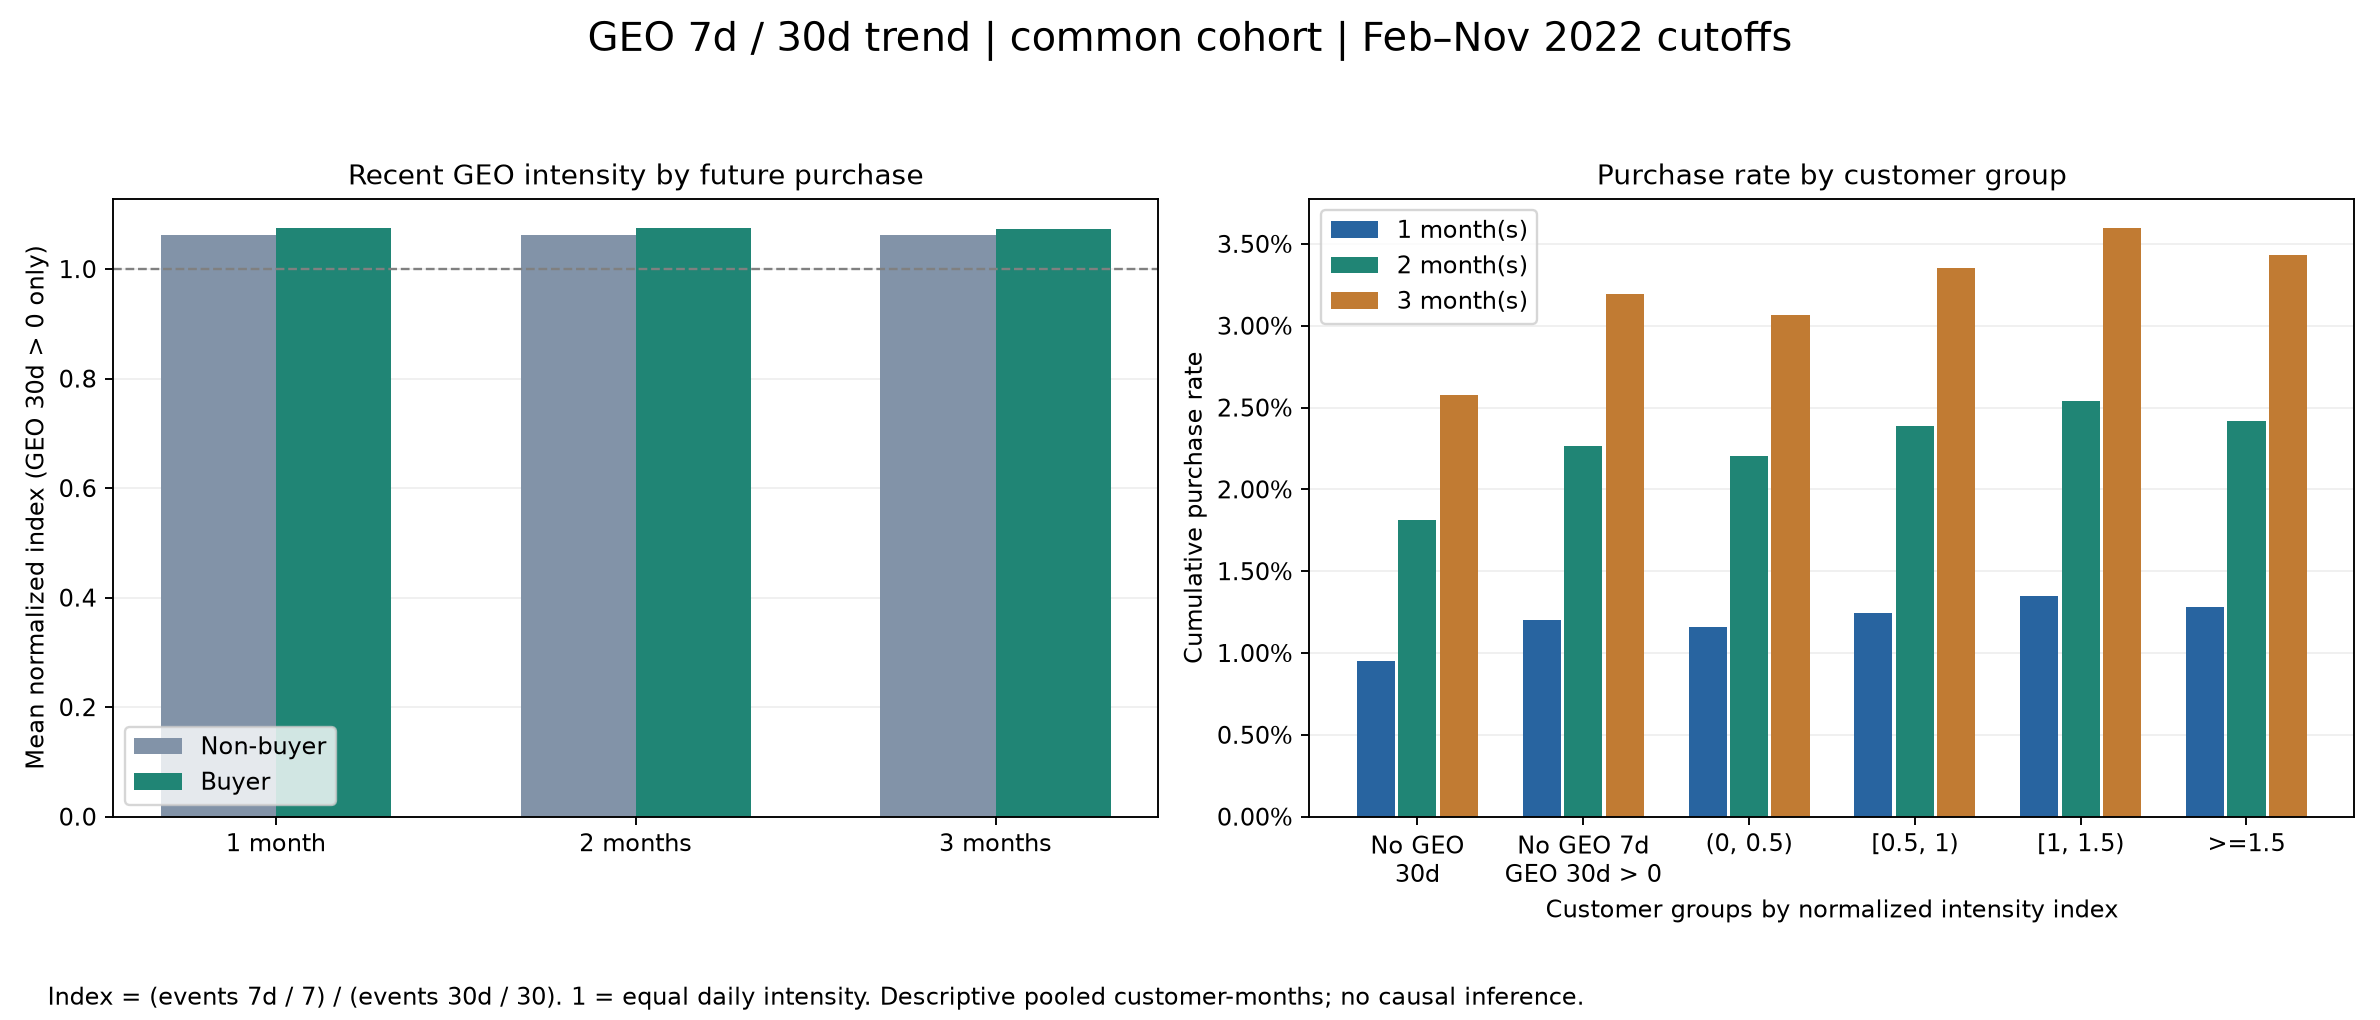

**outputs/geo_trend_purchase/buyer_nonbuyer_summary.csv** — 5 dòng đầu

,horizon,buyer,customer_months,valid_ratio,no_geo30_pct,ratio_mean,ratio_median,index_mean,index_median,index_p90,index_ge1_pct,baseline_rate
0,1,0,990820,574924,41.974930,0.247944,0.233333,1.062616,1.000000,1.714286,50.090273,0.011394
1,1,1,11420,7437,34.877408,0.250811,0.237179,1.074906,1.016484,1.699507,52.050558,0.011394
2,2,0,980507,568234,42.046921,0.247909,0.233333,1.062469,1.000000,1.714286,50.073737,0.021684
3,2,1,21733,14127,34.997469,0.250833,0.236686,1.074998,1.014370,1.706505,51.787358,0.021684
4,3,0,971491,562435,42.106000,0.247888,0.233333,1.062375,1.000000,1.714286,50.048450,0.030680


**outputs/geo_trend_purchase/monthly_buyer_nonbuyer.csv** — 5 dòng đầu

,cutoff,buyer,customer_months,index_mean,index_median,valid_ratio,horizon
0,2022-02-01,0,99183,1.275370,1.224490,59069,1
1,2022-02-01,1,1041,1.329393,1.268821,706,1
2,2022-03-01,0,98657,0.992106,1.008403,59184,1
3,2022-03-01,1,1567,0.975281,1.001855,1091,1
4,2022-04-01,0,98526,0.964193,0.950739,55176,1


**outputs/geo_trend_purchase/trend_band_purchase.csv** — 5 dòng đầu

,trend_band,customer_months,buyers,purchase_rate,horizon,baseline_rate,lift
0,0 < index < 0.5,32007,370,0.011560,1,0.011394,1.014524
1,0.5 <= index < 1,207585,2584,0.012448,1,0.011394,1.092452
2,1 <= index < 1.5,208313,2803,0.013456,1,0.011394,1.180898
3,No GEO 30d,419879,3983,0.009486,1,0.011394,0.832514
4,"No GEO 7d, active prior23",50917,612,0.012020,1,0.011394,1.054859


File kết quả khác: `outputs/geo_trend_purchase/customer_month_trend_labels.parquet`

In [25]:
show_generated_results(__eda_started_ns, 'src/scripts/analyze_geo_trend_purchase.py')